# ✈️ TravelTide – Part 1: Data Cleaning & Exploratory Data Analysis

**Masterschool (MSIT) Data Analytics – Mastery Project**

### 🎯 Project Objective
The objective of this project is to support TravelTide's Head of Marketing, Elena Tarrant, in designing a personalized rewards program that boosts customer engagement and long-term retention.

TravelTide is a fast-growing online travel booking platform with strong search technology, but keeping customers coming back is a challenge. Using a relational database of customer profiles, session logs, flight bookings and hotel reservations, I analyze travel behavior, booking patterns and discount sensitivity. As the Data Analyst on this initiative, my goal is to translate the findings into actionable recommendations: distinct customer segments, each matched to the perk that fits it best.

### 📓 About this notebook
This notebook cleans and explores the session-level cohort table (one row = one browsing session). It is the foundation for Part 2 (user-level features) and Part 3 (rule-based segments, habit-or-luck test and perk mapping, with K-Means, DBSCAN and PCA as a cross-check, plus personas).

**Cohort (Elena's brief):** sessions from 2023-01-04 onward, users with more than 7 sessions in that window → **49,211 sessions from 5,998 users**.

**How the data gets here**
1. SQL is written and tested in VS Code (`sql/session_and_user_base.sql`).
2. With a database connection, this notebook runs that SQL itself and saves the two results in `data/` (1.1) – no ready-made CSV is needed.
3. Without a connection, it reads the CSV export from the local `data` folder, or directly from Google Drive if there is no local copy (works in Colab and VS Code).

**Notebook outline**
1. Setup & data loading
2. First inspection
3. Data cleaning (types, text formatting, missing values, hotel nights, cancellations, age)
4. Derived columns and the user-level table (SQL export, cross-checked)
5. Exploratory data analysis – one source table at a time: sessions, users, flights, hotels, then trips across tables
6. Export & key findings

## 1 – Setup & Data Loading

In [1]:
import importlib, importlib.util, subprocess, sys

# Install missing packages into THIS notebook's Python (sys.executable), so the notebook runs anywhere
# (Colab, VS Code venv, Jupyter). pip name → import name; plotly needs nbformat to draw maps in notebooks.
REQUIRED = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "plotly": "plotly", "nbformat": "nbformat", "airports-py": "airports"}
missing = [pip_name for pip_name, module in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    importlib.invalidate_caches()   # make the new packages importable without a restart
    print("Installed:", ", ".join(missing))

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
PALETTE = ["#3D90F3",  # 0 brand blue – main bars, histograms, home-airport map
           "#A9CCF5",  # 1 pale blue – flat-signal charts, "no discount" pie slice
           "#2E7D8C",  # 2 ocean teal – 3rd gender group, destination map
           "#1B4F8A",  # 3 navy – spare
           "#0D0F14",  # 4 ink – dashed reference lines (age 18, 3,000 km, medians)
           "#79B7F6"]  # 5 light blue – spare
sns.set_palette(PALETTE)

# Theme gradient for charts with several groups (pale green-blue → TravelTide blue → navy)
from matplotlib.colors import LinearSegmentedColormap
TT_CMAP = LinearSegmentedColormap.from_list("traveltide", ["#DDF1E4", "#A8DDB5", "#4EB3D3", "#3D90F3", "#1B4F8A"])
def theme_shades(n):
    """n colors along the theme gradient – one shade per group, light to dark."""
    return [TT_CMAP(x) for x in np.linspace(0.15, 1, n)]

def bar_with_labels(counts, ax, title, horizontal=False, total=None, color=None, rot=0, fontsize=9):
    """Bar chart of shares (%) with 'share % (count)' written on each bar – no separate count/share table needed."""
    total = counts.sum() if total is None else total
    shares = counts / total * 100
    shares.plot(kind="barh" if horizontal else "bar", ax=ax, color=color or theme_shades(len(counts)), rot=rot)   # one shade per bar
    for i, (s, n) in enumerate(zip(shares, counts)):
        if horizontal:
            ax.text(s, i, f"  {s:.1f}% ({n:,})", va="center", fontsize=fontsize)
        else:
            ax.text(i, s, f"{s:.1f}%\n({n:,})", ha="center", va="bottom", fontsize=fontsize)
    if horizontal:
        ax.invert_yaxis(); ax.set_xlim(0, shares.max() * 1.4); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    else:
        ax.set_ylim(0, shares.max() * 1.25); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")

### 1.1 Load the data: database first, CSV export as fallback

The notebook can build its two input tables itself, so no ready-made CSV is needed:

- **Database connection available** (`TRAVELTIDE_URL` as a Colab secret or in a local `.env` file, see 1.2) → the notebook runs `sql/session_and_user_base.sql` against the TravelTide database and saves the two results as `session_level_table.csv` and `user_level_table.csv` in `data/`. Part 2 reads them from there.
- **No connection** → the notebook uses the CSV export instead:
  - **Local copy found** (VS Code repo, or Colab with Google Drive mounted) → the notebook reads it directly from there.
  - **No local copy** → the notebook reads the file **straight from its Google Drive link** into memory. Nothing is downloaded or copied, so no duplicate `data` folders appear.

In [2]:
# *For the Drive fallback, each file is shared as "Anyone with the link – Viewer".*
# Shared project data folder on Google Drive (for reference / browsing):
# https://drive.google.com/drive/folders/13JVW64-U2woCIdmQ1KAQeTyiKwlwaJdc
DRIVE_FOLDER_ID = "13JVW64-U2woCIdmQ1KAQeTyiKwlwaJdc"

# Files used in this notebook: name in the data folder + Google Drive FILE ID
FILES = {
    "sessions": {"name": "session_level_table.csv", "drive_id": "1avNpsUJ7HMcMZGO_KaXZGi_tLT7SxApO"},
    "users":    {"name": "user_level_table.csv",    "drive_id": "1caT1H37JPzKNUo1EcM90eDIjHBe6nQG-"},   # loaded in 4.2 (SQL user_base)
}

# Where the project data folder can be: repo root, notebooks/ subfolder, or Colab with Drive mounted
CANDIDATE_DIRS = [
    Path("data"),
    Path("../data"),
    Path("/content/drive/MyDrive/DS Mastery Project/data"),
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.is_dir()), None)

# --- Option A: build both tables straight from the database with the project SQL (no ready-made CSV) ---
BUILD_FROM_DATABASE = True   # False = always use the CSV export (Option B)
SQL_FILE = next((p for p in [Path("sql/session_and_user_base.sql"), Path("../sql/session_and_user_base.sql")] if p.exists()), None)

def get_db_url():
    """TRAVELTIDE_URL from a Colab secret or the local .env file – None if not set. The URL is never printed."""
    try:
        from google.colab import userdata
        return userdata.get("TRAVELTIDE_URL")
    except Exception:   # not in Colab, or no secret set
        pass
    for env_file in [Path(".env"), Path("../.env")]:   # repo root or one level up from notebooks/
        if env_file.exists():
            for line in env_file.read_text().splitlines():
                if line.strip().startswith("TRAVELTIDE_URL="):
                    return line.split("=", 1)[1].strip().strip('"').strip("'")
    return None

db_url = get_db_url() if BUILD_FROM_DATABASE else None
if db_url and SQL_FILE:
    for pip_name, module in {"psycopg2-binary": "psycopg2", "sqlalchemy": "sqlalchemy"}.items():
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", pip_name], check=True)
    importlib.invalidate_caches()
    from sqlalchemy import create_engine
    engine = create_engine(db_url.replace("postgres://", "postgresql+psycopg2://", 1))   # use the psycopg2 driver

    # The SQL file ends with "Choose ONE output" and two final SELECTs → keep the WITH part, add each SELECT here
    sql_text = SQL_FILE.read_text(encoding="utf-8")
    if "-- Choose ONE output" not in sql_text:
        raise ValueError(f"{SQL_FILE}: marker '-- Choose ONE output' not found – the WITH part can't be separated")
    ctes = sql_text.split("-- Choose ONE output")[0]
    DATA_DIR = DATA_DIR or Path("data")   # no data folder yet → create data/ here
    DATA_DIR.mkdir(exist_ok=True)
    for key, final_select in {"sessions": "SELECT * FROM session_base",
                              "users":    "SELECT * FROM user_base ORDER BY user_id"}.items():
        table = pd.read_sql_query(ctes + final_select, engine)   # numeric columns arrive as floats
        for col in table.select_dtypes("float").columns:          # whole numbers without gaps (e.g. age) → int, as in the export
            if table[col].notna().all() and (table[col] % 1 == 0).all():
                table[col] = table[col].astype("int64")
        table.to_csv(DATA_DIR / FILES[key]["name"], index=False)
        print(f"{FILES[key]['name']}: built from the database with {SQL_FILE.name} → {len(table):,} rows")
else:
    print("No database connection (TRAVELTIDE_URL not set) → using the CSV export")
print("Local data folder:", DATA_DIR.resolve() if DATA_DIR else "not found → reading from Google Drive")

# --- Option B: read the CSV export (local folder first, Google Drive as fallback) ---
def read_export(source):
    # na_values: the SQL export writes missing values as the text "NULL" → read them as real missing values (NaN)
    # encoding_errors: 2 airline names ("AeroMéxico", "Cubana de Aviación") are not UTF-8 encoded in the export;
    # without this, reading crashes with a UnicodeDecodeError. The 2 names are repaired in 3.3.
    return pd.read_csv(source, na_values=["NULL"], encoding_errors="replace")

def load_table(key):
    name, drive_id = FILES[key]["name"], FILES[key]["drive_id"]
    if DATA_DIR is not None and (DATA_DIR / name).exists():
        print(f"{name}: read from local folder")
        return read_export(DATA_DIR / name)
    if not drive_id:
        raise FileNotFoundError(f"{name}: not in the local data folder and no Drive file ID set in FILES")
    print(f"{name}: read directly from Google Drive")
    return read_export(f"https://drive.google.com/uc?export=download&id={drive_id}")

sessions_raw = load_table("sessions")
df = sessions_raw.copy()   # working copy – sessions_raw stays untouched for before/after checks (3.1)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]} | Users: {df['user_id'].nunique():,}")

session_level_table.csv: built from the database with session_and_user_base.sql → 49,211 rows
user_level_table.csv: built from the database with session_and_user_base.sql → 5,998 rows
Local data folder: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data
session_level_table.csv: read from local folder
Rows: 49,211 | Columns: 42 | Users: 5,998


### 1.2 Optional: live queries against the TravelTide database

The analysis runs on the two cohort tables from 1.1. Extra live queries are only needed for checks the cohort tables **cannot** answer – for example, how the gender split looked **before** the cohort filter. Set `RUN_LIVE_QUERIES = True` to run them.

The connection URL is never written into the notebook: we can store it as a Colab secret, or in a local `.env` file (one line `TRAVELTIDE_URL=postgres://...`, listed in `.gitignore`), both named `TRAVELTIDE_URL`.

**Result of the live check (run on 19 Oct 2026):**

| Stage | Users | Female | Male | Other |
|---|---:|---:|---:|---:|
| 1 – all users | 1,020,926 | 44.4 % | 54.8 % | 0.8 % |
| 2 – active since 2023-01-04 | 979,801 | 44.8 % | 54.4 % | 0.8 % |
| 3 – cohort (> 7 sessions) | 5,998 | **88.2 %** | 11.6 % | 0.2 % |

The date filter barely changes the split – it is the **"more than 7 sessions" rule** that turns a male-leaning user base into a cohort of 88 % women (see 3.3).

In [3]:
RUN_LIVE_QUERIES = False   # set to True to run the live check below (needs TRAVELTIDE_URL, see above)

if RUN_LIVE_QUERIES:
    import os
    for pip_name, module in {"psycopg2-binary": "psycopg2", "sqlalchemy": "sqlalchemy", "python-dotenv": "dotenv"}.items():
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", pip_name], check=True)
    from sqlalchemy import create_engine, text

    # Connection URL: Colab secret, otherwise the local .env file (never written into the notebook)
    try:
        from google.colab import userdata
        db_url = userdata.get("TRAVELTIDE_URL")
    except ImportError:
        from dotenv import load_dotenv
        load_dotenv()                      # reads TRAVELTIDE_URL from .env in the project folder
        db_url = os.environ["TRAVELTIDE_URL"]
    engine = create_engine(db_url.replace("postgres://", "postgresql+psycopg2://", 1))   # use the installed psycopg2 driver

    gender_by_stage = pd.read_sql(text('''
        WITH active AS (SELECT DISTINCT user_id FROM sessions WHERE session_start >= '2023-01-04'),
             cohort AS (SELECT user_id FROM sessions WHERE session_start >= '2023-01-04'
                        GROUP BY user_id HAVING COUNT(*) > 7),
             stages AS (
                 SELECT '1 all users' AS stage, gender FROM users
                 UNION ALL SELECT '2 active since 2023-01-04', u.gender FROM users u JOIN active a USING (user_id)
                 UNION ALL SELECT '3 cohort (> 7 sessions)',  u.gender FROM users u JOIN cohort c USING (user_id))
        SELECT stage, gender, COUNT(*) AS users,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY stage), 1) AS pct
        FROM stages GROUP BY stage, gender ORDER BY stage, gender
    '''), engine)
    display(gender_by_stage)

### 1.3 First look: the four source tables inside the session table

The session-level table joins four database tables, which makes 42 columns at once. To keep it readable, the columns are grouped by their **source table** and each table is rebuilt from the session table:

- `users` → one row per user (`drop_duplicates` on `user_id`)
- `sessions` → one row per session (session columns only)
- `flights` / `hotels` → one row per booked trip that has a flight / hotel (`drop_duplicates` on `trip_id`)

The four tables are only a **view** of the original Postgres tables. All analysis runs on the two SQL exports: `session_level_table.csv` (this table) and `user_level_table.csv` (one row per user, loaded in 4.2). A check showed the rebuilt tables match the separate database exports exactly (5,998 users, 13,717 flights, 14,313 hotels).

**Why one joined table instead of four separate ones?**

- **Same cohort everywhere:** the cohort filter (date + more than 7 sessions) is applied once in SQL, so users, sessions, flights and hotels can never drift apart. Four separate tables would each need the same filter and joins again in Python.
- **The questions span tables:** most of Elena’s questions combine sources – e.g. trip spend needs the flight fare and the hotel price; a hotel-only trip only gets its city from the hotels table; a cancellation is recorded in `sessions` but cancels a flight or hotel. In one table these are simple column operations.
- **Two levels, matching the two tasks:** the **session table** is used to clean and explore behavior; the user table (one row per user) is the level at which segments and perks are assigned. Trips are handled inside both: `valid_booking` marks the kept trips in the session table (3.6), and the user table aggregates only those (`valid_trips`).
- **Nothing is lost**: the four tables can be rebuilt from it at any time (above), and they match the database exports exactly.

In [4]:
# Which columns come from which database table
COLUMN_GROUPS = {
    "users": ["user_id", "birthdate", "gender", "married", "has_children", "home_country", "home_city",
              "home_airport", "home_airport_lat", "home_airport_lon", "sign_up_date"],
    "sessions": ["session_id", "user_id", "trip_id", "session_start", "session_end", "page_clicks",
                 "flight_discount", "flight_discount_amount", "flight_booked",
                 "hotel_discount", "hotel_discount_amount", "hotel_booked", "cancellation"],
    "flights": ["trip_id", "origin_airport", "destination", "destination_airport", "seats", "return_flight_booked",
                "departure_time", "return_time", "checked_bags", "trip_airline",
                "destination_airport_lat", "destination_airport_lon", "base_fare_usd"],
    "hotels": ["trip_id", "hotel_name", "nights", "rooms", "check_in_time", "check_out_time", "hotel_per_room_usd"],
}
# Every column belongs to one source table – except the helper the SQL cohort step adds:
# session_count = number of sessions per user in the window, used for the "more than 7 sessions" rule
print("Column not from the 4 source tables (SQL helper):", set(df.columns) - set(sum(COLUMN_GROUPS.values(), [])))

df_users    = df[COLUMN_GROUPS["users"]].drop_duplicates("user_id")
df_sessions = df[COLUMN_GROUPS["sessions"]]
df_flights  = df.loc[df["destination"].notna(), COLUMN_GROUPS["flights"]].drop_duplicates("trip_id") # only trips with a flight have a destination 
df_hotels   = df.loc[df["hotel_name"].notna(), COLUMN_GROUPS["hotels"]].drop_duplicates("trip_id")  # only trips with a hotel have a hotel name

tables = {"users": df_users, "sessions": df_sessions, "flights": df_flights, "hotels": df_hotels}
for name, table in tables.items():
    print(f"\n{name.upper()} – {table.shape[0]:,} rows × {table.shape[1]} columns")
    display(table.head())

Column not from the 4 source tables (SQL helper): {'session_count'}

USERS – 5,998 rows × 11 columns


,user_id,birthdate,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,sign_up_date
0,23557,1958-12-08,F,True,False,usa,new york,LGA,40.777,-73.872,2021-07-22
1,120851,1972-09-25,F,True,True,usa,santa ana,SNA,33.676,-117.868,2022-03-13
2,229108,1998-05-28,F,False,False,usa,burlington,BTV,44.472,-73.153,2022-06-27
3,264470,1978-11-05,F,False,True,usa,bakersfield,BFL,35.433,-119.057,2022-07-27
4,348863,1957-01-13,F,True,False,usa,san antonio,SKF,29.384,-98.581,2022-10-04



SESSIONS – 49,211 rows × 13 columns


,session_id,user_id,trip_id,session_start,session_end,page_clicks,flight_discount,flight_discount_amount,flight_booked,hotel_discount,hotel_discount_amount,hotel_booked,cancellation
0,23557-3f6bd6be250e45959b33b808ac525df6,23557,NaN,2023-01-04 19:30:00,2023-01-04 19:33:53,32,False,NaN,False,False,NaN,False,False
1,120851-bfeb515377f44fdbbb9d9642dc0c7178,120851,NaN,2023-01-04 19:49:00,2023-01-04 19:49:37,5,False,NaN,False,False,NaN,False,False
2,229108-d2b0f9bc7aea425189cb943fa1706810,229108,NaN,2023-01-04 20:44:00,2023-01-04 20:45:29,12,True,0.2,False,False,NaN,False,False
3,264470-71e8f4d269aa44308aa34ffd1c2d0c18,264470,NaN,2023-01-04 22:50:00,2023-01-04 22:50:59,8,False,NaN,False,False,NaN,False,False
4,348863-e3c9ba813fc84210a236a3a11e364859,348863,NaN,2023-01-04 08:57:00,2023-01-04 08:58:15,10,False,NaN,False,False,NaN,False,False



FLIGHTS – 13,717 rows × 13 columns


,trip_id,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd
155,510365-edd2f605ca324ff78cbe5cc1236b6ea7,BOS,toronto,YTZ,3.0,True,2023-01-09 14:00:00,2023-01-24 14:00:00,0.0,Porter Airlines,43.862,-79.370,379.11
353,512201-d198cb30dbe945a58808812558288792,SJC,new york,LGA,1.0,True,2023-01-14 11:00:00,2023-01-23 11:00:00,1.0,United Airlines,40.640,-73.779,781.52
423,476714-f7d36ece6b46409cbe363123d363bd40,CMH,oklahoma city,OKC,2.0,True,2023-01-15 08:00:00,2023-01-16 08:00:00,1.0,Virgin Atlantic Airways,35.393,-97.601,512.76
756,515243-5a7e18c70ef64fc1b221ab42bb7b1197,HNL,las vegas,LSV,2.0,True,2023-01-14 07:00:00,2023-01-19 07:00:00,1.0,United Airlines,36.080,-115.152,1790.49
919,515398-1eecb60b58b24615b7a8a23595c98f58,LGA,los angeles,LSQ,2.0,True,2023-01-13 07:00:00,2023-01-14 07:00:00,1.0,United Airlines,33.942,-118.408,1651.04



HOTELS – 14,313 rows × 7 columns


,trip_id,hotel_name,nights,rooms,check_in_time,check_out_time,hotel_per_room_usd
155,510365-edd2f605ca324ff78cbe5cc1236b6ea7,Choice Hotels - toronto,12.0,3.0,2023-01-09 16:52:24.600,2023-01-22 11:00:00,168.0
353,512201-d198cb30dbe945a58808812558288792,Shangri-La - new york,8.0,1.0,2023-01-14 18:09:21.555,2023-01-23 11:00:00,171.0
423,476714-f7d36ece6b46409cbe363123d363bd40,Banyan Tree - oklahoma city,0.0,2.0,2023-01-15 11:44:13.425,2023-01-15 11:00:00,294.0
975,517491-f17c9a923a054db2955c3f56a7d8486e,Banyan Tree - fort worth,3.0,1.0,2023-01-13 10:18:23.850,2023-01-16 11:00:00,154.0
989,517735-a543e7016da749e09ee511d199f6f3dc,Fairmont - jacksonville,6.0,2.0,2023-01-13 10:09:21.960,2023-01-19 11:00:00,247.0


In [5]:
table_info = {
    "users":    ("dimension", "one row per user",                 "user_id"),
    "sessions": ("fact",      "one row per browsing session",     "session_id"),
    "flights":  ("fact",      "one row per booked flight (trip)", "trip_id"),
    "hotels":   ("fact",      "one row per booked hotel (trip)",  "trip_id"),
}
overview = pd.DataFrame([
    {"table": name, "type": kind, "grain": grain, "key": key,
     "rows": len(tables[name]), "columns": tables[name].shape[1], "key_unique": tables[name][key].is_unique}
    for name, (kind, grain, key) in table_info.items()
])
display(overview)
print("Trips with flight AND hotel:", len(set(df_flights["trip_id"]) & set(df_hotels["trip_id"])))

,table,type,grain,key,rows,columns,key_unique
0,users,dimension,one row per user,user_id,5998,11,True
1,sessions,fact,one row per browsing session,session_id,49211,13,True
2,flights,fact,one row per booked flight (trip),trip_id,13717,13,True
3,hotels,fact,one row per booked hotel (trip),trip_id,14313,7,True


Trips with flight AND hotel: 11931


**How the tables connect**

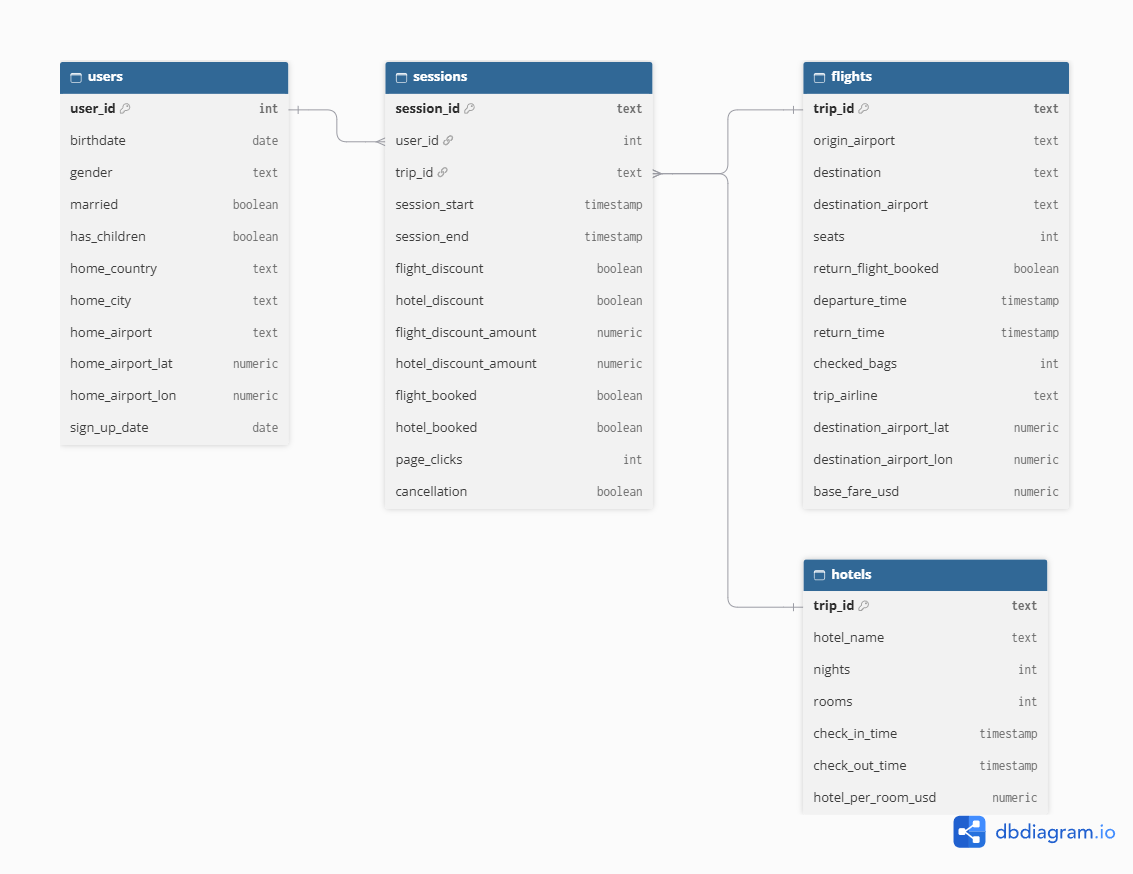

In [6]:
# Show the database schema (ERD) – works from the repo root or from notebooks/
from IPython.display import Image, display
erd = next((p for p in [Path("../images/TravelTide_ERD.png"), Path("images/TravelTide_ERD.png")] if p.exists()), None)
display(Image(filename=erd, width=1000)) if erd else print("ERD image not found – expected in images/TravelTide_ERD.png")

- `users` is the **dimension** table (who the customer is); `sessions`, `flights` and `hotels` are **fact** tables (what happened).
- One user has many sessions; a session has a `trip_id` only if something was booked (or canceled).
- A trip can have a flight, a hotel, or both – that's why flights and hotels are joined with **LEFT JOINs** in the SQL, so browsing sessions are kept.
- `df_users`, `df_flights` etc. are handy for a quick look at one table; the cleaning below works on the full joined table `df`.

## 2 – First Inspection

In [7]:
df.head(5).T

,0,1,2,3,4
session_id,23557-3f6bd6be250e45959b33b808ac525df6,120851-bfeb515377f44fdbbb9d9642dc0c7178,229108-d2b0f9bc7aea425189cb943fa1706810,264470-71e8f4d269aa44308aa34ffd1c2d0c18,348863-e3c9ba813fc84210a236a3a11e364859
user_id,23557,120851,229108,264470,348863
trip_id,NaN,NaN,NaN,NaN,NaN
session_start,2023-01-04 19:30:00,2023-01-04 19:49:00,2023-01-04 20:44:00,2023-01-04 22:50:00,2023-01-04 08:57:00
session_end,2023-01-04 19:33:53,2023-01-04 19:49:37,2023-01-04 20:45:29,2023-01-04 22:50:59,2023-01-04 08:58:15
page_clicks,32,5,12,8,10
flight_discount,False,False,True,False,False
flight_discount_amount,NaN,NaN,0.2,NaN,NaN
flight_booked,False,False,False,False,False
hotel_discount,False,False,False,False,False


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49211 entries, 0 to 49210
Data columns (total 42 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   session_id               49211 non-null  str    
 1   user_id                  49211 non-null  int64  
 2   trip_id                  16702 non-null  str    
 3   session_start            49211 non-null  str    
 4   session_end              49211 non-null  str    
 5   page_clicks              49211 non-null  int64  
 6   flight_discount          49211 non-null  bool   
 7   flight_discount_amount   8282 non-null   float64
 8   flight_booked            49211 non-null  bool   
 9   hotel_discount           49211 non-null  bool   
 10  hotel_discount_amount    6205 non-null   float64
 11  hotel_booked             49211 non-null  bool   
 12  cancellation             49211 non-null  bool   
 13  session_count            49211 non-null  int64  
 14  birthdate                49211 no

In [9]:
# Cohort sanity checks: every user must have at least 8 sessions, all sessions inside the window
print("Min sessions per user:", df.groupby("user_id")["session_id"].count().min())
print("Session window:", df["session_start"].min(), "→", df["session_end"].max())
print("Duplicate session_ids:", df["session_id"].duplicated().sum(), "| Fully duplicated rows:", df.duplicated().sum())

Min sessions per user: 8
Session window: 2023-01-04 00:01:00 → 2023-07-28 20:08:52.000000


Duplicate session_ids: 0 | Fully duplicated rows: 0


**Observations:** 42 columns from four joined tables. Dates are stored as text, several integer columns are floats (because of missing values), and text columns use mixed casing. There are no duplicate sessions, and every user has at least 8 sessions, so the cohort filter worked as intended.

## 3 – Data Cleaning

**Guiding rule:** no session rows are dropped. Removing rows would change the cohort (users could fall below 8 sessions) and break the link to Elena's definition. Problems are fixed or flagged instead.

### 3.1 Date and time columns

In [10]:
datetime_cols = ["session_start", "session_end", "departure_time", "return_time", "check_in_time", "check_out_time"]
date_cols = ["birthdate", "sign_up_date"]

# ISO8601 handles mixed precision (some check-in times carry microseconds)
for col in datetime_cols:
    df[col] = pd.to_datetime(df[col], format="ISO8601")
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d")

print("Unparsed values:", df[datetime_cols + date_cols].isna().sum().sum() - sessions_raw[datetime_cols + date_cols].isna().sum().sum())
print("session_end before session_start:", (df["session_end"] < df["session_start"]).sum())
print("return before departure:", (df["return_time"] < df["departure_time"]).sum(),
      "| return equal to departure:", (df["return_time"] == df["departure_time"]).sum(), "(see 3.2)")

Unparsed values: 0
session_end before session_start: 0
return before departure: 0 | return equal to departure: 70 (see 3.2)


### 3.2 Integer and boolean columns

`seats`, `checked_bags`, `rooms` and `nights` are counts, but pandas reads them as floats because sessions without a flight or hotel have no value. They become **nullable integers (`Int64`)** – missing stays missing.

> Filling them with 0 would be wrong: a browsing session did not book "0 seats", it booked no flight at all. Zeros would pull every average down.

In [11]:
count_cols = ["seats", "checked_bags", "rooms", "nights"]
df[count_cols] = df[count_cols].astype("Int64")
df[count_cols].dtypes

seats           Int64
checked_bags    Int64
rooms           Int64
nights          Int64
dtype: object

`return_flight_booked` only applies to sessions with a flight. It is missing for all 34,891 sessions without a flight (correct) and for 50 flight sessions. All 50 are **cancellation sessions**, which carry no flight details at all, so they stay missing (unknown) instead of being guessed as one-way. The column becomes a nullable boolean so missing stays missing.

> Careful: `astype(bool)` on a column with `NaN` turns every `NaN` into `True`.

In [12]:
display(pd.crosstab(df["flight_booked"], df["return_flight_booked"], dropna=False))
no_info = df["flight_booked"] & df["return_flight_booked"].isna()
print("Flight sessions without return info:", no_info.sum(), "| of these cancellation sessions:", df.loc[no_info, "cancellation"].sum())

df["return_flight_booked"] = df["return_flight_booked"].astype("boolean")   # nullable: missing stays missing
df["return_flight_booked"].value_counts(dropna=False)

return_flight_booked,False,True,NaN
flight_booked,,,
False,0,0,34891
True,618,13652,50


Flight sessions without return info: 50 | of these cancellation sessions: 50


return_flight_booked
<NA>     34941
True     13652
False      618
Name: count, dtype: Int64

#### Return-flight consistency (flights table)

In [13]:
# One row per booked flight (= the flights table from 1.3), now with cleaned types
fl = df.loc[df["destination"].notna()].drop_duplicates("trip_id")
rfb, dep, ret = fl["return_flight_booked"], fl["departure_time"], fl["return_time"]
consistency = pd.DataFrame({"flights": {
    "missing return-flight indicator":       rfb.isna().sum(),
    "one-way – no return time":              ((rfb == False) & ret.isna()).sum(),
    "one-way – return time present":         ((rfb == False) & ret.notna()).sum(),
    "return flight – missing return time":   ((rfb == True) & ret.isna()).sum(),
    "return flight – return time present":   ((rfb == True) & ret.notna()).sum(),
    "missing departure time":                dep.isna().sum(),
    "return before departure":               (ret < dep).sum(),
    "return equal to departure":             (ret == dep).sum(),
}})
display(consistency)

same = fl[ret == dep]
print("Return = departure:", len(same), "| all flight-only (no hotel):", (~same["hotel_booked"]).all(),
      "| return always on the same clock time as departure:", (fl["return_time"].dt.time == fl["departure_time"].dt.time)[ret.notna()].mean() == 1)

,flights
missing return-flight indicator,0
one-way – no return time,597
one-way – return time present,0
return flight – missing return time,0
return flight – return time present,13120
missing departure time,0
return before departure,0
return equal to departure,70


Return = departure: 70 | all flight-only (no hotel): True | return always on the same clock time as departure: True


**70 flights with return time = departure time** (e.g. LGA → Portland, out 30 Jan 07:00, back 30 Jan 07:00). Leaving and returning at the same minute is not possible, so these timestamps are **not real** – they come from how the dataset was generated:

- Every return flight in the data leaves at exactly the **same clock time** as the outbound flight, a whole number of days later (`return_time = departure_time + N days`, checked above for all 13,120 return flights).
- For packages, N follows the hotel stay, so it is at least 1. For flight-only trips there is no hotel, and in 70 cases N came out as **0** → identical timestamps. All 70 are flight-only bookings.

**What this means for the analysis:**
- **Fix?** Not possible – the true return date is unknown, and any guessed value (e.g. +1 day) would be invented data.
- **Filter?** Not needed – seats, fare, distance and booking date of these 70 bookings are valid, and removing them would change the cohort.
- **Impact:** none. The project never uses the flight return time: trip length comes from hotel nights, timing from the trip start. The 70 bookings are **kept**, and this note documents why the timestamps look odd.

### 3.3 Text formatting and unused columns

Text values are standardized for readable tables and charts (Tableau, Streamlit, slides):

| Column | Rule | Example |
|---|---|---|
| `home_country` | country name | `usa` → `USA`, `canada` → `Canada` |
| `home_city`, `destination` | Title Case (apostrophes stay lower case) | `new york` → `New York`, `xi'an` → `Xi'an` |
| airport codes | upper case | `lga` → `LGA` |
| `hotel_name` | Title Case, double spaces removed, **brand and city kept** | `Banyan Tree  - oklahoma city` → `Banyan Tree - Oklahoma City` |
| `hotel_city` (new) | city part of `hotel_name` | `Oklahoma City` |
| `trip_airline` | 2 names repaired (not UTF-8 in the export, see 1.1) | `AeroM�xico` → `AeroMéxico` |
| `gender` | kept as `F` / `M` / `O` | – |

**Why the hotel city stays in the name:** one chain runs hotels in many cities (957 hotels from only 20 chains). Shortening the name to the brand would merge e.g. all Accor hotels into one. The city is also the **only location of hotel-only trips** – they have no flight `destination`.

**Kept, but not used for segmentation:** `origin_airport` (identical to `home_airport` for 99.7 % of flights) and `trip_airline` (airlines play no role in the perks). They keep the cleaned table complete, e.g. for Tableau tooltips.

In [14]:
print("origin_airport == home_airport:", round((df.loc[df["flight_booked"], "origin_airport"] == df.loc[df["flight_booked"], "home_airport"]).mean() * 100, 1), "%")

def title_case(s):
    # Title Case every word; letters after an apostrophe stay lower case ("Xi'an", not "Xi'An")
    return s.str.strip().str.title().str.replace(r"'(\w)", lambda m: "'" + m[1].lower(), regex=True)

for col in ["home_city", "destination"]:
    df[col] = title_case(df[col])
for col in ["home_airport", "origin_airport", "destination_airport"]:
    df[col] = df[col].str.strip().str.upper()
df["home_country"] = df["home_country"].str.strip().map({"usa": "USA", "canada": "Canada"})
df["gender"] = df["gender"].str.strip().str.upper()

# hotel_name = "Brand - City": keep both parts, fix 2 brand spellings that Title Case gets wrong
df["hotel_name"] = (title_case(df["hotel_name"].str.replace(r"\s+", " ", regex=True))
                    .replace({r"^Nh Hotel": "NH Hotel", r"^Intercontinental": "InterContinental"}, regex=True))
df["hotel_city"] = df["hotel_name"].str.split(" - ").str[-1]

# repair the 2 airline names that were not UTF-8 encoded in the export (see 1.1)
df["trip_airline"] = df["trip_airline"].replace({"AeroM\ufffdxico": "AeroMéxico", "Cubana de Aviaci\ufffdn": "Cubana de Aviación"})

# check: hotel city vs flight destination on package trips (flight + hotel, not canceled)
package = df["flight_booked"] & df["hotel_booked"] & ~df["cancellation"]
print("hotel_city == destination (package sessions):", round((df.loc[package, "hotel_city"] == df.loc[package, "destination"]).mean() * 100, 1), "%")
print(f"Hotels: {df['hotel_name'].nunique()} from {df['hotel_name'].str.split(' - ').str[0].nunique()} chains")
df[["home_country", "home_city", "home_airport", "destination", "destination_airport", "hotel_name", "hotel_city", "trip_airline"]].dropna().head()

origin_airport == home_airport: 99.7 %


hotel_city == destination (package sessions): 100.0 %
Hotels: 957 from 20 chains


,home_country,home_city,home_airport,destination,destination_airport,hotel_name,hotel_city,trip_airline
155,USA,Boston,BOS,Toronto,YTZ,Choice Hotels - Toronto,Toronto,Porter Airlines
353,USA,San Jose,SJC,New York,LGA,Shangri-La - New York,New York,United Airlines
423,USA,Columbus,CMH,Oklahoma City,OKC,Banyan Tree - Oklahoma City,Oklahoma City,Virgin Atlantic Airways
975,USA,Nashville,BNA,Fort Worth,FTW,Banyan Tree - Fort Worth,Fort Worth,American Airlines
989,USA,Memphis,MEM,Jacksonville,NZC,Fairmont - Jacksonville,Jacksonville,American Airlines


In [15]:
user_first = df.groupby("user_id")[["gender", "home_country"]].first()
for col in ["gender", "home_country"]:
    vc = user_first[col].value_counts()
    print(f"{col}: " + " | ".join(f"{k} {v:,} ({v / len(user_first):.1%})" for k, v in vc.items()))
print("Destinations:", df["destination"].nunique(), "| Home cities:", df["home_city"].nunique())

gender: F 5,292 (88.2%) | M 695 (11.6%) | O 11 (0.2%)
home_country: USA 4,991 (83.2%) | Canada 1,007 (16.8%)
Destinations: 125 | Home cities: 105


**Gender** (printed above): 88 % of cohort users are female (5,292 of 5,998), 12 % male (695) and 11 users (0.2 %) Other (`O`). The `O` users are **kept**: dropping them would remove sessions from the cohort, and gender is not used as a segmentation feature.

**Caution – the female majority comes from the cohort filter, not from TravelTide's customer base.** Across all 1,020,926 users only **44.4 % are female** (54.8 % male); after the date filter it is still 44.8 %. The **"more than 7 sessions" rule** then keeps just 5,998 users (0.6 % of the 979,801 active users) – and 88.2 % of them are women (live check in 1.2). So the share must not be read as "TravelTide's customers are women", and gender is **not** used to choose perks; any perk communication that leans on gender would only fit this small, very active cohort.

#### Full airport names

Airport codes like `TCM` or `BIF` are hard to read in tables and charts. The `airports-py` package looks up the full name and type of each IATA code. Two codes are missing from the package because the airports are closed (Berlin Schönefeld `SXF`, Berlin Tempelhof `THF`), so their names are added by hand.

In [16]:
from airports import airport_data

CLOSED_AIRPORTS = {"SXF": "Berlin Schönefeld Airport (closed)", "THF": "Berlin Tempelhof Airport (closed)"}

def airport_info(code):
    hits = airport_data.get_airport_by_iata(code)
    if hits:
        return {"airport_code": code, "airport_name": hits[0]["airport"], "airport_type": hits[0]["type"],
                "scheduled_service": str(hits[0]["scheduled_service"]).upper() == "TRUE", "country_code": hits[0]["country_code"]}
    return {"airport_code": code, "airport_name": CLOSED_AIRPORTS.get(code, "Not found"),
            "airport_type": "closed", "scheduled_service": False, "country_code": None}

codes = sorted(set(df["home_airport"].dropna()) | set(df["destination_airport"].dropna()))
airport_lookup = pd.DataFrame([airport_info(c) for c in codes])

# Add the full names to the session table (useful for Tableau tooltips and readable tables)
names = airport_lookup.set_index("airport_code")["airport_name"]
df["home_airport_name"] = df["home_airport"].map(names)
df["destination_airport_name"] = df["destination_airport"].map(names)

# Lookup table: how often each airport is a home airport (users) or a destination (flights)
home_users = df.groupby("home_airport")["user_id"].nunique().rename("home_users")
dest_flights = df[df["flight_booked"] & ~df["cancellation"]].groupby("destination_airport")["session_id"].count().rename("destination_flights")
airport_lookup = (airport_lookup.set_index("airport_code")
                  .join([home_users, dest_flights]).fillna({"home_users": 0, "destination_flights": 0})
                  .astype({"home_users": int, "destination_flights": int})
                  .sort_values("home_users", ascending=False))
print(f"{len(airport_lookup)} airports | home airports: {(airport_lookup['home_users'] > 0).sum()} | destinations: {(airport_lookup['destination_flights'] > 0).sum()}")
airport_lookup.head(15)

261 airports | home airports: 159 | destinations: 183


,airport_name,airport_type,scheduled_service,country_code,home_users,destination_flights
airport_code,,,,,,
LGA,LaGuardia Airport,large_airport,True,US,362,959
LAX,Los Angeles International Airport,large_airport,True,US,325,492
JFK,John F. Kennedy International Airport,large_airport,True,US,318,987
DAL,Dallas Love Field,large_airport,True,US,117,367
YYC,Calgary International Airport,large_airport,True,CA,101,343
SFO,San Francisco International Airport,large_airport,True,US,80,242
AUS,Austin-Bergstrom International Airport,large_airport,True,US,78,247
SJC,Norman Y. Mineta San Jose International Airport,large_airport,True,US,75,101
BNA,Nashville International Airport,large_airport,True,US,74,166


In [17]:
# Home airports that are not regular passenger airports (military bases, small fields)
unusual = airport_lookup[(airport_lookup["home_users"] > 0) &
                         ((airport_lookup["airport_type"] != "large_airport") | (~airport_lookup["scheduled_service"]))]
print(f"Home airports that are not large scheduled airports: {len(unusual)} "
      f"({unusual['home_users'].sum()} users, {unusual['home_users'].sum() / df['user_id'].nunique():.1%})")
unusual[["airport_name", "airport_type", "scheduled_service", "home_users"]].head(15)

Home airports that are not large scheduled airports: 66 (1643 users, 27.4%)


,airport_name,airport_type,scheduled_service,home_users
airport_code,,,,
YKZ,Buttonville Municipal Airport,medium_airport,False,66
YMX,Mirabel International Airport,medium_airport,False,64
UGN,Waukegan National Airport,small_airport,False,61
LUF,Luke Air Force Base,medium_airport,False,60
YZD,Downsview Airport,small_airport,False,53
LOU,Bowman Field,medium_airport,False,53
PNE,North Philadelphia Airport,medium_airport,False,51
NZY,North Island Naval Air Station,medium_airport,False,50
FTW,Fort Worth Meacham International Airport,medium_airport,False,50


**Data note:** about 27 % of users (1,643 of 5,998, printed above) have a home airport that is not a large airport with scheduled flights – some are even military bases (e.g. `TCM` McChord Air Force Base for Tacoma, `LUF` Luke Air Force Base for Phoenix, `NZY` North Island Naval Air Station for San Diego). The dataset seems to assign each home city an airport code nearby, not the airport people really fly from. Airport names are therefore used for readability only, and distances are calculated between coordinates – which stay valid either way.

**Same name, different city:** three home city names stand for two different cities each – Portland (Oregon `PDX` / Maine `PWM`), Jacksonville and Fayetteville. Wherever users are grouped by home location (e.g. the map in 5.2.4), the airport code is used as well, so they are not merged. Destination names are safe: all airports with the same destination name lie within 150 km of each other (same metro area).

### 3.4 Missing values: structural or a problem?

Missing values in this table are expected when they belong to something that was not booked. The check below confirms that every gap is explained by the booking flags.

In [18]:
flight_cols = ["origin_airport", "destination", "destination_airport", "destination_airport_name", "seats", "checked_bags", "departure_time", "trip_airline",
               "destination_airport_lat", "destination_airport_lon", "base_fare_usd"]
hotel_cols = ["hotel_name", "hotel_city", "nights", "rooms", "check_in_time", "check_out_time", "hotel_per_room_usd"]

# Expected reason for a gap in each column group
expected_gap = {
    **{c: ~df["flight_booked"] | df["cancellation"] for c in flight_cols},
    **{c: ~df["hotel_booked"] | df["cancellation"] for c in hotel_cols},
    "return_time": ~df["flight_booked"] | df["cancellation"] | (df["return_flight_booked"] == False),
    "return_flight_booked": ~df["flight_booked"] | df["cancellation"],
    "flight_discount_amount": ~df["flight_discount"] | df["cancellation"],
    "hotel_discount_amount": ~df["hotel_discount"] | df["cancellation"],
    "trip_id": ~df["flight_booked"] & ~df["hotel_booked"],
}
checks = df.isna().sum().to_frame("missing_total").query("missing_total > 0")
checks["missing_%"] = (checks["missing_total"] / len(df) * 100).round(1)
checks["explained"] = [(df[c].isna() & expected_gap[c]).sum() for c in checks.index]
checks["unexplained"] = checks["missing_total"] - checks["explained"]
checks.sort_values("missing_total", ascending=False)

,missing_total,missing_%,explained,unexplained
hotel_discount_amount,43006,87.4,43006,0
flight_discount_amount,40929,83.2,40929,0
return_time,35559,72.3,35559,0
destination_airport,34941,71.0,34941,0
destination,34941,71.0,34941,0
seats,34941,71.0,34941,0
origin_airport,34941,71.0,34941,0
destination_airport_name,34941,71.0,34941,0
return_flight_booked,34941,71.0,34941,0
departure_time,34941,71.0,34941,0


- **Flight and hotel columns:** missing when no flight / hotel was booked → structural, no imputation. The few extra gaps (50 flight, 193 hotel) are all on **cancellation sessions**, which repeat the booking flags but not always the trip details – they are excluded from travel behavior anyway (3.6).
- **`return_time`:** additionally missing for the 618 one-way flights (`return_flight_booked = False`) → correct.
- **`trip_id`:** missing for the 32,509 browsing-only sessions → correct.
- **Discount amounts:** missing when no discount was offered. 610 sessions have a discount flag but no amount – these are exactly the cancellation sessions (see 3.6). Note: a discount *flag* on a browsing session means a discount was **offered**, not used; "discount used" is only measured on booked trips (section 4).

In [19]:
print("Discount flag without amount:", (df["flight_discount"] & df["flight_discount_amount"].isna()).sum(),
      "| all on cancellation sessions:", (df["flight_discount"] & df["flight_discount_amount"].isna() & df["cancellation"]).sum())
print("Flight discounts offered in sessions without a flight booking:",
      (df["flight_discount"] & ~df["flight_booked"]).sum(), "of", df["flight_discount"].sum())

Discount flag without amount: 610 | all on cancellation sessions: 610
Flight discounts offered in sessions without a flight booking: 6312 of 8892


### 3.5 Hotel nights

The raw `nights` column contains negative values and often disagrees with the check-in/check-out dates. Comparing it with the **calendar nights** (check-out date minus check-in date) shows the pattern: raw `nights` counts full 24-hour periods, so a stay from 14:47 to 11:00 the next morning shows 0 nights instead of 1.

**Decision:** use calendar nights (`nights_calc`). Stays with 0 or negative calendar nights (check-out on or before check-in) are invalid hotel dates → `nights_calc` is set to missing and flagged, the session itself is kept.

**Exact time vs. calendar date:** comparing exact timestamps, 231 sessions have check-out before check-in – but most of these are same-day stays where check-out is a few hours earlier than check-in. By calendar date, only 27 are truly negative and 412 start and end on the same date (crosstab columns −1 and 0) → 439 sessions with invalid hotel dates. On the trip level (one row per hotel booking, as in the hotels table) this is 430 trips, matching the hotels table (14,313 rows) exactly. Of these, 421 are valid (not canceled) bookings.

The trips themselves are real: all 430 are flight + hotel packages, and 412 have a valid return flight 1–3 days after departure; check-in falls on the departure day as usual. Only the hotel check-out date is broken – so the trip is kept and only `nights_calc` (and the trip spend) is set to missing. Estimating the nights from the flight dates was considered but not used: on valid trips the hotel stay matches the flight span in only 40 % of cases (otherwise it is up to 3 nights shorter), so it would remain a guess.

In [20]:
calendar_nights = (df["check_out_time"].dt.normalize() - df["check_in_time"].dt.normalize()).dt.days
display(pd.crosstab(df["nights"].clip(-2, 4), calendar_nights.clip(-2, 4), rownames=["raw nights"], colnames=["calendar nights"]))

df["invalid_hotel_dates"] = calendar_nights.le(0) & df["hotel_booked"] # compute invalid hotel dates (check-out ≤ check-in) only for booked hotels
df["nights_calc"] = calendar_nights.where(calendar_nights > 0).astype("Int64") # compute nights from check-in/out only if valid (positive) – otherwise NaN
print("\nRaw nights < 0:", (df["nights"] < 0).sum(),
      "| raw ≠ calendar:", (df["nights"] != calendar_nights)[df["hotel_booked"]].sum(),
      "| invalid hotel dates:", df["invalid_hotel_dates"].sum(),
      f"({df['invalid_hotel_dates'].sum() / df['hotel_booked'].sum():.1%} of hotel sessions)")
df = df.drop(columns="nights")

calendar nights,-1.0,0.0,1.0,2.0,3.0,4.0
raw nights,,,,,,
-2,1,0,0,0,0,0
-1,26,80,0,0,0,0
0,0,332,896,0,0,0
1,0,0,908,2297,0,0
2,0,0,0,921,1931,0
3,0,0,0,0,703,1301
4,0,0,0,0,0,5330



Raw nights < 0: 107 | raw ≠ calendar: 8848 | invalid hotel dates: 439 (2.9% of hotel sessions)


### 3.6 Cancellations

A cancellation is recorded as a **second session with the same `trip_id`** (`cancellation = True`, booking flags repeated). That is why 413 hotel trips appear twice in the session table, with the same user and the same check-in and check-out – the hotels table itself has one row per trip (14,313 unique `trip_id`s). Counting both sessions would double-count the trip, and counting the original booking would treat a canceled trip as travel. A **booking session** is a session in which something was booked: it has a `trip_id` and is not a cancellation (16,092 sessions). Together with the 610 cancellation sessions, these are the 16,702 sessions with a `trip_id` – exactly the sessions where `flight_booked` or `hotel_booked` is True.

**Decision:** flag every session whose trip was later canceled (`trip_cancelled`). A **valid booking** is a booking session whose trip was never canceled.

**Note:** 7 of the 610 canceled trips were booked before Jan 4, 2023, so only their cancellation session is in the time frame (16,702 sessions with a trip_id = 16,092 bookings + 610 cancellations). They don’t change the valid bookings; they add one canceled trip for 7 users, which we keep because the cancellation happened inside the time frame. The opposite case – a trip canceled after Jul 28, 2023 – can’t be seen in the data and counts as valid.

In [21]:
cancelled_ids = set(df.loc[df["cancellation"], "trip_id"])
df["trip_cancelled"] = df["trip_id"].isin(cancelled_ids)
df["valid_booking"] = df["trip_id"].notna() & ~df["cancellation"] & ~df["trip_cancelled"]   # trip_id exists AND trip never canceled

print("Cancellation sessions:", df["cancellation"].sum(), "| canceled trips:", len(cancelled_ids)) # each canceled trip has exactly one cancellation session
print("Sessions with a trip_id:", df["trip_id"].notna().sum(), "| unique trips:", df["trip_id"].nunique())
print("Valid (kept) bookings:", df["valid_booking"].sum())
print("Users without any valid booking:", (~df.groupby("user_id")["valid_booking"].any()).sum())

# canceled trips whose booking session lies before the time frame (only the cancellation is inside it)
booked_ids = set(df.loc[df["trip_id"].notna() & ~df["cancellation"], "trip_id"])
print("Canceled trips booked before Jan 4, 2023:", len(cancelled_ids - booked_ids))

Cancellation sessions: 610 | canceled trips: 610
Sessions with a trip_id: 16702 | unique trips: 16099
Valid (kept) bookings: 15489
Users without any valid booking: 556
Canceled trips booked before Jan 4, 2023: 7


### 3.7 Age and account tenure

**Which date to measure age at?** All behavior in the cohort happens between 2023-01-04 and 2023-07-28. Age is a user attribute used at user level, so every user needs **one** age:

- **Reference date = last session end in the data (2023-07-28)** ✅ – same reference for everyone, works for the 556 users who never booked, results don't change when the notebook is re-run later.
- Today's date ❌ – adds 3+ years to everyone and changes every time the notebook runs.
- Age at each booking or trip ❌ – differs from the reference age by at most 7 months, is missing for non-bookers and gives several ages per user.

Age is computed in exact years (birthday reached or not), not `days // 365`, which drifts with leap years.

In [22]:
REF_DATE = df["session_end"].max().normalize()
print("Reference date:", REF_DATE.date())

def age_on(birth, ref):
    # Exact age in full years: subtract one if the birthday hasn't happened yet in the reference year
    before_birthday = (birth.dt.month > ref.month) | ((birth.dt.month == ref.month) & (birth.dt.day > ref.day))
    return (ref.year - birth.dt.year - before_birthday.astype(int)).astype("Int64")

df["age"] = age_on(df["birthdate"], REF_DATE)
df["tenure_months"] = ((REF_DATE - df["sign_up_date"]).dt.days / 30.44).round(1)

users = df.groupby("user_id")[["age", "tenure_months"]].first()
display(users.describe().round(1))
n_minor = (users["age"] < 18).sum()
print(f"\nUsers under 18 on the reference date: {n_minor} of {len(users):,} ({n_minor / len(users):.1%})")

Reference date: 2023-07-28


,age,tenure_months
count,5998.0,5998.0
mean,40.9,6.2
std,12.0,1.2
min,16.0,2.3
25%,34.0,5.7
50%,41.0,6.2
75%,48.0,6.6
max,88.0,24.2



Users under 18 on the reference date: 246 of 5,998 (4.1%)


**Data note:** 246 of 5,998 cohort users (4.1 %) are under 18 on the reference date (youngest: 16). They are **kept** – they are real active accounts – but flagged with `is_minor`. 233 of them were born in 2006 – see the birth-year chart below.

Recommendation for TravelTide: check the sign-up age rules; for the rewards program, perks for these users may need a guardian or adult account.

In [23]:
df["is_minor"] = df["age"] < 18
df = df.drop(columns=["birthdate", "sign_up_date"])

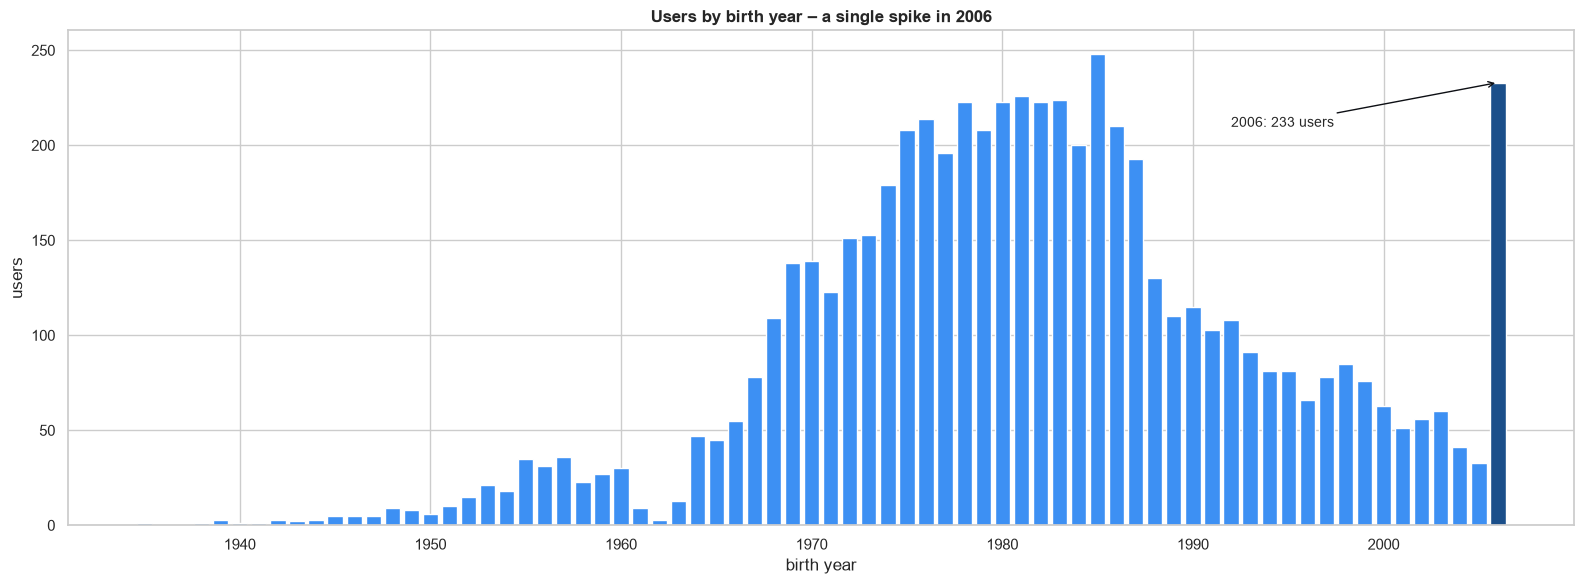

Born in 2006: 233 users (average per year 2000–2005: 51)
Of the 246 minors, 233 were born in 2006 | 24% of them have children at age 16–17


In [24]:
# Birth year per user (from the raw export, before birthdate was replaced by age)
users_birth = sessions_raw.drop_duplicates("user_id").set_index("user_id")["birthdate"]
birth_year = pd.to_datetime(users_birth).dt.year
counts = birth_year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(counts.index, counts.values, color=[PALETTE[3] if y == 2006 else PALETTE[0] for y in counts.index])
ax.annotate(f"2006: {counts[2006]} users", xy=(2006, counts[2006]), xytext=(1992, counts[2006] * 0.9),
            arrowprops=dict(arrowstyle="->", color=PALETTE[4]), fontsize=10)
ax.set_title("Users by birth year – a single spike in 2006", fontweight="bold")
ax.set_xlabel("birth year"); ax.set_ylabel("users")
plt.tight_layout(); plt.show()

users_2006 = df.drop_duplicates("user_id").set_index("user_id").loc[birth_year[birth_year == 2006].index]
print(f"Born in 2006: {len(users_2006)} users (average per year 2000–2005: {counts.loc[2000:2005].mean():.0f})")
print(f"Of the {df.drop_duplicates('user_id')['is_minor'].sum()} minors, {users_2006['is_minor'].sum()} were born in 2006 | "
      f"{users_2006['has_children'].mean():.0%} of them have children at age {users_2006['age'].min()}–{users_2006['age'].max()}")

**Birth year 2006 stands out:** 233 users were born in 2006 – about four times the yearly average of the years before (~51 per year for 2000–2005). They are 233 of the 246 minors, and 24 % of them "have children" at age 16–17. Most likely 2006 is the youngest year the sign-up form accepts, so many of these birthdates are placeholders. The users and their behavior are kept; only their **age** is treated with caution – which is why the Dreamers age pattern (5.2.3) is based on the 18–24 and 55+ groups, not on the under-18 group.

### 3.8 Outliers

In [25]:
outlier_cols = ["page_clicks", "base_fare_usd", "hotel_per_room_usd", "seats", "checked_bags", "rooms", "nights_calc"]

def iqr_summary(s):
    q1, q3 = s.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
    return pd.Series({"median": s.median(), "q3": q3, "upper_fence": upper, "max": s.max(),
                      "n_above_fence": (s > upper).sum(),
                      "share_above_fence_%": round((s > upper).mean() * 100, 1)})

pd.DataFrame({c: iqr_summary(df[c].dropna().astype(float)) for c in outlier_cols}).T.round(1)

,median,q3,upper_fence,max,n_above_fence,share_above_fence_%
page_clicks,13.0,22.0,46.0,566.0,2103.0,4.3
base_fare_usd,381.8,600.6,1200.9,21548.0,867.0,6.1
hotel_per_room_usd,148.0,222.0,406.5,1376.0,680.0,4.6
seats,1.0,1.0,1.0,8.0,2215.0,15.5
checked_bags,1.0,1.0,2.5,8.0,169.0,1.2
rooms,1.0,1.0,1.0,4.0,2276.0,15.5
nights_calc,3.0,5.0,9.5,43.0,1250.0,8.7


**How to read the chart:** each panel shows one variable on a log scale, so long tails fit on one axis.
- **Pale shape (violin):** where most values lie – the wider, the more sessions have that value.
- **Blue box:** the middle 50 % of values (Q1–Q3); the dark line inside is the median.
- **Dashed line:** the outlier fence (Q3 + 1.5 × IQR); every **navy dot** to its right is one outlier.
- **Title:** median, number and share of outliers (same numbers as the table above).

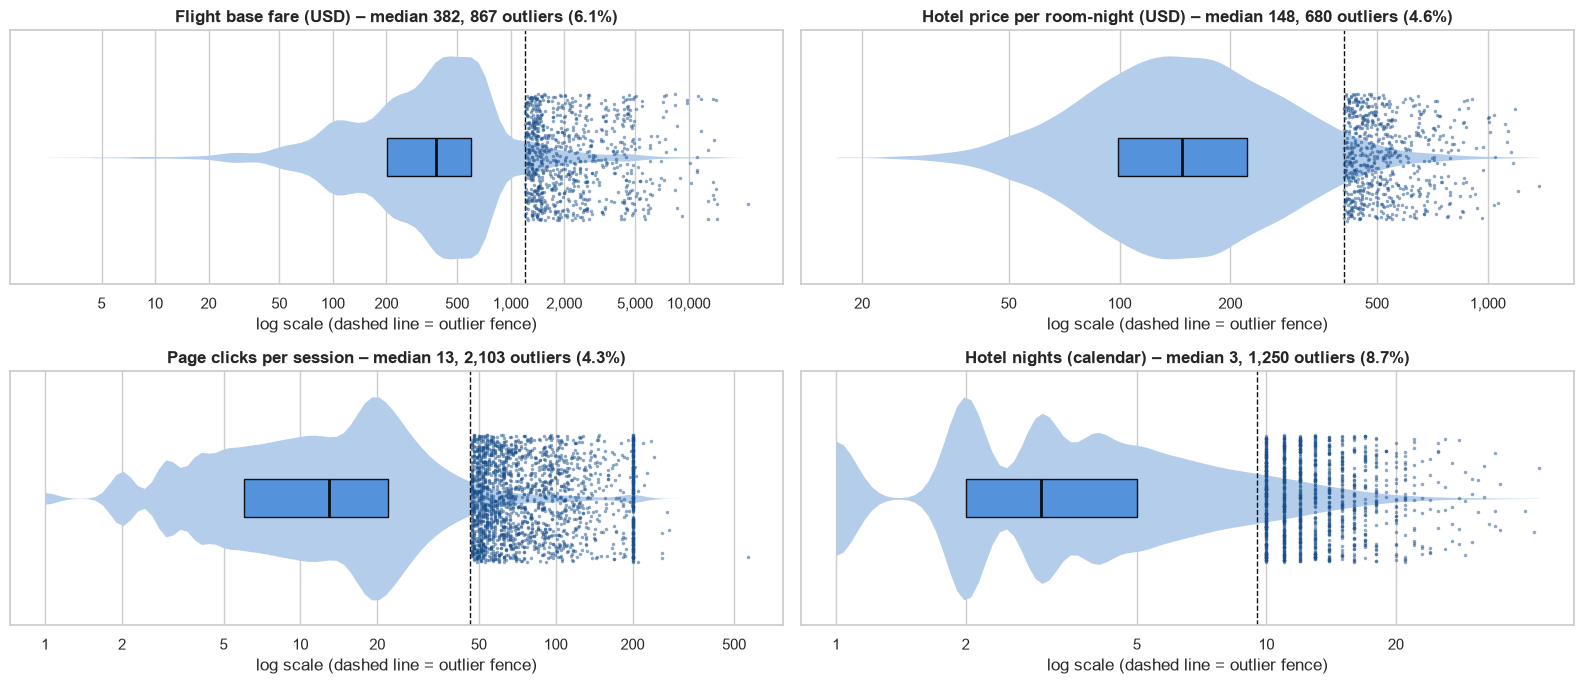

In [26]:
# "Raincloud" view per variable: violin = shape of the distribution, slim box = Q1–median–Q3,
# navy dots = every value above the IQR fence (Q3 + 1.5 × IQR); log scale so the long tails fit
outlier_plots = {"base_fare_usd": "Flight base fare (USD)", "hotel_per_room_usd": "Hotel price per room-night (USD)",
                 "page_clicks": "Page clicks per session", "nights_calc": "Hotel nights (calendar)"}
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
for ax, (col, title) in zip(axes.flat, outlier_plots.items()):
    s = df[col].dropna().astype(float)
    s = s[s > 0]
    q1, q3 = s.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
    out = s[s > fence]
    sns.violinplot(x=np.log10(s), ax=ax, color=PALETTE[1], inner=None, cut=0, linewidth=0, density_norm="width")
    sns.boxplot(x=np.log10(s), ax=ax, width=0.15, showfliers=False, whis=0, showcaps=False, color=PALETTE[0],
                medianprops=dict(color=PALETTE[4], lw=2), boxprops=dict(edgecolor=PALETTE[4]))
    sns.stripplot(x=np.log10(out), ax=ax, color=PALETTE[3], size=2.5, alpha=.5, jitter=0.25)
    ax.axvline(np.log10(fence), color=PALETTE[4], ls="--", lw=1)
    ticks = [t for t in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000] if s.min() <= t <= s.max() * 1.05]
    ax.set_xticks(np.log10(ticks), [f"{t:,}" for t in ticks])
    ax.set_xlabel("log scale (dashed line = outlier fence)")
    ax.set_title(f"{title} – median {s.median():,.0f}, {len(out):,} outliers ({len(out) / len(s):.1%})", fontweight="bold")
plt.tight_layout(); plt.show()

**What the outliers are:**
- **Flight base fare – 867 outliers (6.1 %):** every single one is a long-haul flight (> 3,000 km) or a booking with 2+ seats (89 % and 81 % of the outliers). The fare simply grows with distance and party size (see 5.3.4) – expensive, but expected.
- **Hotel price per night – 680 outliers (4.6 %):** spread over all chains rather than one luxury brand, and the most expensive night costs $1,376 – plausible premium rooms, no data errors.
- **Page clicks – 2,103 outliers (4.3 %):** the vertical "wall" of dots at 200 clicks is the **cancellation sessions**: they stop at exactly 200 clicks (98 % of the sessions near 200 are cancellations), and 490 of the click outliers are cancellations. The rest are long research sessions before a booking.
- **Hotel nights – 1,250 outliers (8.7 %, stays of 10+ nights):** half of them are hotel-only trips, although hotel-only trips make up only 17 % of all stays → long stays are a real travel style (Hotel Stayers), not noise.

**Decision:** outliers are **kept**. They are plausible and partly define segments (Long-haul Travelers, Hotel Stayers). Features are scaled before clustering in Part 3, and a check there shows that the extreme users don’t change the clusters (Part 3, 5.5).

## 4 – Derived Columns and the User-Level Table

### 4.1 Derived session & trip columns

Only columns that are used later in the project are created here. Each feeds a user-level feature in Part 2.

| New column | Definition | Used for |
|---|---|---|
| `session_minutes` | session end − start | engagement check |
| `booking_type` | browsing / flight + hotel / flight only / hotel only / cancellation | trip mix, Hotel Stayers, Package Travelers |
| `trip_start`, `start_weekday`, `weekend_start` | earlier of departure and check-in; Fri/Sat start | weekend check (Part 3, 3.2) |
| `lead_days` | days from booking session to trip start | flat-signal check |
| `trip_city` | flight destination, or hotel city for hotel-only trips | Favorite-City Returners |
| `distance_km` | great-circle (haversine) distance, home airport → destination airport; same formula as in the SQL | Long-haul Travelers |
| `discount_used` | discount on the **booked** part of a valid booking (flight discount on a booked flight, hotel discount on a booked hotel) – see data note below | Deal Hunters |
| `trip_spend_usd` | fare and hotel cost after discounts; **missing** for the 421 bookings with invalid hotel dates (hotel cost unknown – $0 would make them look far cheaper) | value per segment |

In [27]:
df["session_minutes"] = (df["session_end"] - df["session_start"]).dt.total_seconds() / 60

df["booking_type"] = np.select(
    [df["cancellation"],
     df["flight_booked"] & df["hotel_booked"],
     df["flight_booked"],
     df["hotel_booked"]],
    ["cancellation", "flight + hotel", "flight only", "hotel only"],
    default="browsing")

df["trip_start"] = df[["departure_time", "check_in_time"]].min(axis=1)
df["start_weekday"] = df["trip_start"].dt.day_name()
df["weekend_start"] = df["trip_start"].dt.dayofweek.isin([4, 5]).where(df["trip_start"].notna())   # Fri, Sat
df["lead_days"] = (df["trip_start"].dt.normalize() - df["session_end"].dt.normalize()).dt.days

# trip city: hotel-only trips have no flight destination → use the hotel city, so repeat visits are not missed
df["trip_city"] = df["destination"].fillna(df["hotel_city"])

# great-circle distance on a sphere (Earth radius 6,371 km) – vectorized, so all rows are computed at once
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_km(df["home_airport_lat"], df["home_airport_lon"],
                                 df["destination_airport_lat"], df["destination_airport_lon"]).round(0)

# discount only counts for the part that was booked (the flags also show offers on the part NOT booked – see data note)
df["discount_used"] = ((df["flight_booked"] & df["flight_discount"]) | (df["hotel_booked"] & df["hotel_discount"])).where(df["valid_booking"])
flight_cost = df["base_fare_usd"].fillna(0) * (1 - df["flight_discount_amount"].fillna(0))
hotel_cost = (df["hotel_per_room_usd"].fillna(0) * df["rooms"].fillna(0).astype(float)
              * df["nights_calc"].fillna(0).astype(float) * (1 - df["hotel_discount_amount"].fillna(0)))
df["trip_spend_usd"] = (flight_cost + hotel_cost).round(2).where(df["valid_booking"] & ~df["invalid_hotel_dates"])

**Data note – discount flags show offers, not use.** `flight_discount` and `hotel_discount` record which discounts were **offered** in a session – also for the part a user did *not* book (e.g. a flight-only booking can carry `hotel_discount = True` with an amount, although no hotel was bought). Counting every offer would treat 549 bookings as discounted although the discount wasn’t used (cell below). **Decision:** a discount only counts for the booked part – here and in the SQL (`any_discount` in `valid_trips`), so `discount_share` in the user table uses the same definition.

In [28]:
# How many valid bookings change with the corrected discount definition?
valid_rows = df["valid_booking"]
offered_any = (df["flight_discount"] | df["hotel_discount"]) & valid_rows   # every discount offered in the session
used = df.loc[valid_rows, "discount_used"].astype(bool)                     # corrected: discount on the booked part only
print(f"Valid bookings: {valid_rows.sum():,}")
print(f"  with any discount OFFERED in the session:      {offered_any.sum():,} ({offered_any.sum() / valid_rows.sum():.1%})  ← if every offer counted")
print(f"  with a discount on the BOOKED part (used now): {used.sum():,} ({used.mean():.1%})")
print(f"  offer only on the part not booked:             {(offered_any[valid_rows] & ~used).sum():,} – no longer counted")

Valid bookings: 15,489
  with any discount OFFERED in the session:      4,069 (26.3%)  ← if every offer counted
  with a discount on the BOOKED part (used now): 3,520 (22.7%)
  offer only on the part not booked:             549 – no longer counted


### 4.2 User-level table (SQL `user_base`) – load and cross-check

`user_level_table.csv` is the second SQL export: one row per cohort user with demographics and pre-aggregated session and trip metrics (29 columns). It is the **source for all user-level analysis** (5.2 and Part 2). Text columns get the same formatting as in 3.3. The cross-check below confirms that the export agrees with the cleaned session table – and that it is the **latest export** (it includes the hotel-city fix for repeat cities, the spend fix for invalid hotel dates and the discount fix from 4.1).

In [29]:
users_raw = load_table("users")
users_lvl = users_raw.copy()
users_lvl["home_city"] = title_case(users_lvl["home_city"])
users_lvl["home_airport"] = users_lvl["home_airport"].str.strip().str.upper()
users_lvl["home_country"] = users_lvl["home_country"].str.strip().map({"usa": "USA", "canada": "Canada"})
users_lvl["gender"] = users_lvl["gender"].str.strip().str.upper()
print(f"Rows: {len(users_lvl):,} | Columns: {users_lvl.shape[1]}")
display(users_lvl.head())

# Cross-check: same numbers from the SQL user table and from the cleaned session table
valid = df[df["valid_booking"]]
all_users = df["user_id"].unique()
repeat_city = valid.groupby(["user_id", "trip_city"]).size().groupby("user_id").max().reindex(all_users, fill_value=0)
spend_trips = valid.groupby("user_id")["trip_spend_usd"].count().reindex(all_users, fill_value=0)
age_sessions = df.groupby("user_id")["age"].first()
# users with ≥ 50 % discounted trips (same definition as discount_share in the SQL) – shows whether the export has the discount fix
discount_users = (valid.assign(d=valid["discount_used"].astype(float)).groupby("user_id")["d"].mean().round(2) >= 0.5).sum()
cross = pd.DataFrame({
    "user_level_table": [len(users_lvl), users_lvl["valid_trips"].sum(), (users_lvl["valid_trips"] == 0).sum(),
                         (users_lvl["max_visits_same_city"] >= 2).sum(), users_lvl["avg_spend_per_trip_usd"].isna().sum(),
                         (users_lvl.set_index("user_id")["age"] == age_sessions.astype(int)).sum(),
                         (users_lvl["discount_share"] >= 0.5).sum()],
    "session_table":    [len(all_users), len(valid), (~df.groupby("user_id")["valid_booking"].any()).sum(),
                         (repeat_city >= 2).sum(), (spend_trips == 0).sum(), len(all_users), discount_users],
}, index=["users", "valid trips", "users with 0 valid trips (Dreamers)", "users with a repeat city (2+ visits)",
          "users without trip spend", "users with identical age", "users with ≥ 50 % discounted trips"])
cross["match"] = np.where(cross["user_level_table"] == cross["session_table"], "✅", "⚠️")
display(cross)
if (cross["match"] != "✅").any():
    print("⚠️ user_level_table.csv does not match – most likely an older export: re-run the SQL and export it again.")

user_level_table.csv: read from local folder
Rows: 5,998 | Columns: 29


,user_id,age,gender,married,has_children,home_country,home_city,home_airport,tenure_months,session_count,avg_session_min,avg_page_clicks,cancelled_trips,valid_trips,flights,hotels,combo_share,flight_only_share,hotel_only_share,avg_seats,avg_rooms,avg_bags,avg_nights,avg_distance_km,weekend_start_share,discount_share,total_spend_usd,avg_spend_per_trip_usd,max_visits_same_city
0,23557,64,F,True,False,USA,New York,LGA,24,8,1.28,10.25,0,2,0,2,0.0,0.0,1.0,NaN,1.5,NaN,10.0,NaN,0.0,0.5,3670.50,1835.25,1
1,94883,51,F,True,False,USA,Kansas City,MCI,17,8,1.13,9.13,0,2,2,2,1.0,0.0,0.0,1.5,1.5,0.5,1.0,1454.0,0.0,0.0,1094.09,547.05,1
2,101486,50,F,True,True,USA,Tacoma,TCM,17,8,2.04,16.38,0,2,1,2,0.5,0.0,0.5,1.0,1.5,0.0,4.5,965.0,1.0,0.0,2641.91,1320.96,1
3,101961,42,F,True,False,USA,Boston,BOS,17,8,1.96,15.75,0,5,5,5,1.0,0.0,0.0,1.0,1.0,0.4,4.4,1322.0,0.4,0.2,4035.69,807.14,1
4,106907,44,F,True,True,USA,Miami,TNT,17,8,12.65,30.00,1,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


,user_level_table,session_table,match
users,5998,5998,✅
valid trips,15489,15489,✅
users with 0 valid trips (Dreamers),556,556,✅
users with a repeat city (2+ visits),805,805,✅
users without trip spend,582,582,✅
users with identical age,5998,5998,✅
users with ≥ 50 % discounted trips,1281,1281,✅


## 5 – Exploratory Data Analysis

The EDA follows the four source tables from 1.3: **sessions** and **users** first, then **flights** and **hotels**, and finally **trips across tables**, where flight, hotel, price and timing come together. Each part answers a few concrete questions.

In [30]:
bookings = df[df["valid_booking"]].copy()          # one row per kept trip (15,489)

# Users: the SQL user-level table (4.2) + home coordinates from the session table for the map
users = (users_lvl.set_index("user_id")
         .join(df.groupby("user_id")[["home_airport_lat", "home_airport_lon"]].first())) # add home coordinates for the map
users["age_years"] = users["age"].astype(float)
users["gender_label"] = users["gender"].map({"F": "Female", "M": "Male", "O": "Other"})
users["family_status"] = np.select(
    [users["married"] & users["has_children"], users["married"], users["has_children"]],
    ["Married, children", "Married, no children", "Single, children"], default="Single, no children")
users["status"] = np.where(users["valid_trips"] > 0, "Booker", "Dreamer")
print(f"Sessions: {len(df):,} | valid bookings: {len(bookings):,} | users: {len(users):,}")

Sessions: 49,211 | valid bookings: 15,489 | users: 5,998


### 5.1 Sessions – how do customers use the website?
*Source table: `sessions` (one row per browsing session, 49,211 rows).*

#### 5.1.1 Activity over time

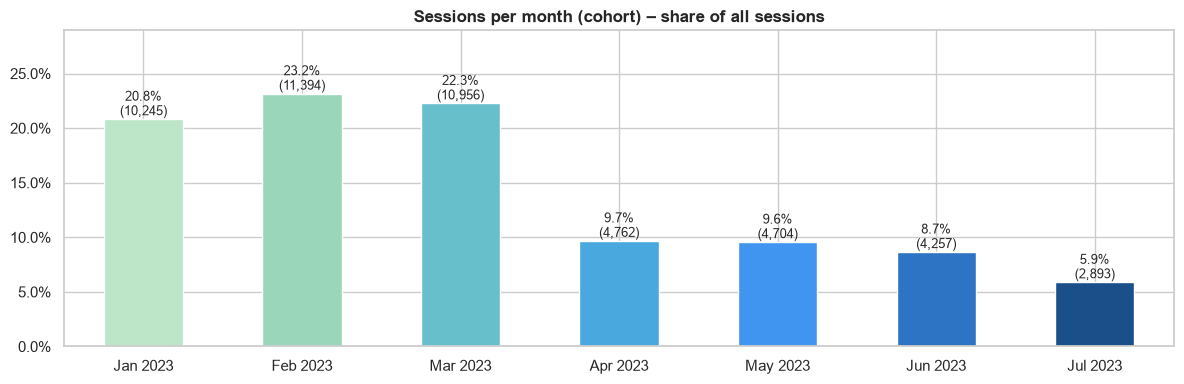

Avg sessions per month: Jan–Mar 10,865 | Apr–Jun 4,574 | ratio 2.4x


In [31]:
monthly = df["session_start"].dt.to_period("M").value_counts().sort_index() # sessions per month (cohort) – share of all sessions
monthly.index = monthly.index.strftime("%b %Y") # convert PeriodIndex to string for plotting
fig, ax = plt.subplots(figsize=(12, 4))
bar_with_labels(monthly, ax, "Sessions per month (cohort) – share of all sessions")
plt.tight_layout(); plt.show()

q1 = monthly.iloc[0:3].mean(); q2 = monthly.iloc[3:6].mean()   # Jan–Mar vs Apr–Jun (July is partial)
print(f"Avg sessions per month: Jan–Mar {q1:,.0f} | Apr–Jun {q2:,.0f} | ratio {q1 / q2:.1f}x")

Session volume is more than twice as high in January–March as in April–July (about 10,900 vs 4,600 sessions per month, ratio 2.4×, printed above; July is a partial month, data ends 28 Jul). Part of this is likely seasonal trip planning; part may be how the cohort was built. Behavior is therefore summarized per user over the full window rather than compared month by month.

#### 5.1.2 Session outcome

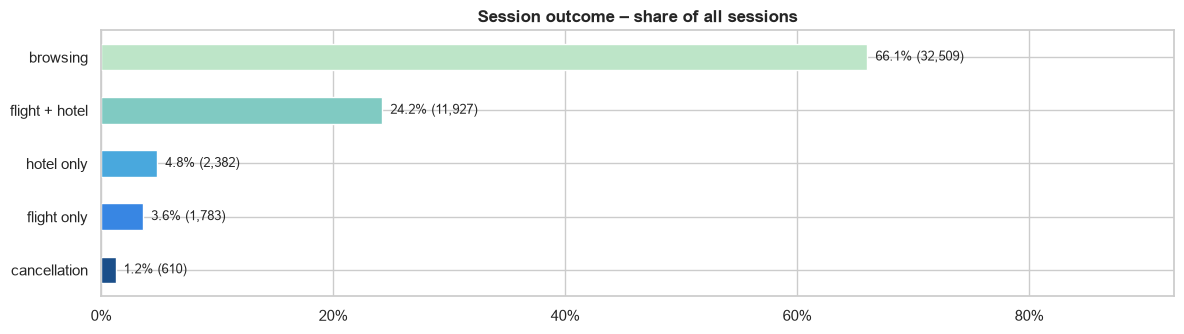

In [32]:
order = ["browsing", "flight + hotel", "hotel only", "flight only", "cancellation"]
fig, ax = plt.subplots(figsize=(12, 3.5))
bar_with_labels(df["booking_type"].value_counts().reindex(order), ax, "Session outcome – share of all sessions", horizontal=True)
plt.tight_layout(); plt.show()

About two thirds of all sessions end without a booking (32,509 of 49,211 = 66.1 %). Among bookings, flight + hotel packages dominate (24.2 % of sessions); hotel-only (4.8 %) and flight-only trips (3.6 %) are smaller but distinct groups. Cancellations are rare (610 sessions, 1.2 %).

#### 5.1.3 Engagement by outcome

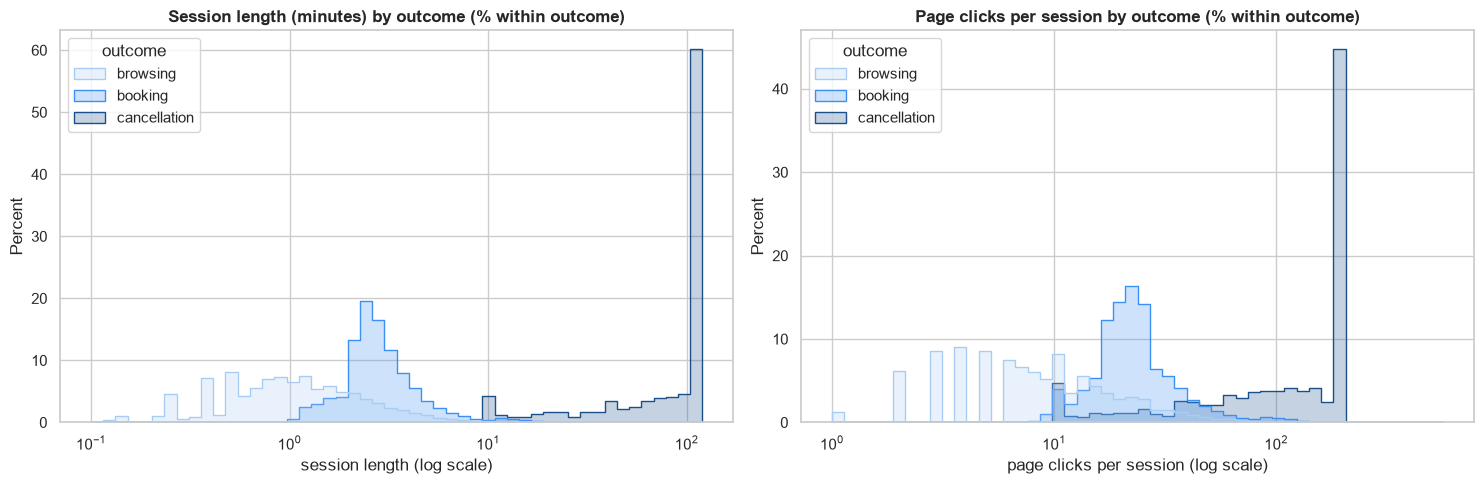

,sessions,share_%,median_minutes,median_clicks
outcome,,,,
browsing,32509,66.1,1.0,8.0
booking,16092,32.7,2.7,22.0
cancellation,610,1.2,120.0,145.5


In [33]:
# Third dimension: session length and page clicks per outcome (browsing / booking / cancellation)
outcome_order = ["browsing", "booking", "cancellation"]
sessions_out = df.assign(outcome=df["booking_type"].where(df["booking_type"].isin(["browsing", "cancellation"]), "booking"))
outcome_colors = dict(zip(outcome_order, [PALETTE[1], PALETTE[0], PALETTE[3]]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, title in zip(axes, ["session_minutes", "page_clicks"], ["Session length (minutes)", "Page clicks per session"]):
    sns.histplot(data=sessions_out, x=col, hue="outcome", hue_order=outcome_order, stat="percent", common_norm=False,
                 element="step", alpha=.25, bins=50, log_scale=True, ax=ax, palette=outcome_colors)
    ax.set_title(f"{title} by outcome (% within outcome)", fontweight="bold"); ax.set_xlabel(f"{title.split(' (')[0].lower()} (log scale)")
plt.tight_layout(); plt.show()

engagement = sessions_out.groupby("outcome").agg(sessions=("session_id", "count"), median_minutes=("session_minutes", "median"),
                                                 median_clicks=("page_clicks", "median")).reindex(outcome_order)
engagement.insert(1, "share_%", (engagement["sessions"] / len(df) * 100).round(1))
display(engagement.round(1))

Booking sessions are longer and busier than browsing sessions (median about 2.7 vs 1 minute, 22 vs 8 clicks – table above). **Cancellation sessions** stand out with a median of 120 minutes and about 146 clicks – most likely how the system logs a cancellation, not real browsing; they are excluded from travel behavior anyway (3.6). Engagement mainly shows *whether* someone books, so it is not used as a separate segmentation feature.

#### 5.1.4 Flat session signals

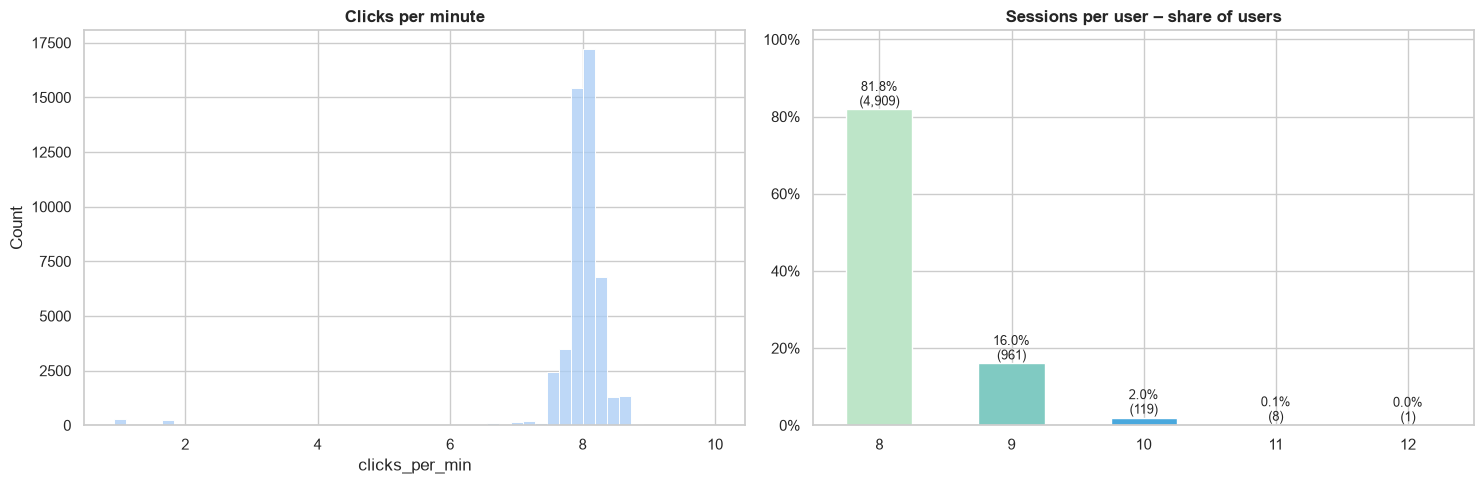

,count,mean,std,min,25%,50%,75%,max
clicks_per_min,49211.0,7.95,0.78,0.93,7.89,8.04,8.17,10.0


In [34]:
df["clicks_per_min"] = df["page_clicks"] / df["session_minutes"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df["clicks_per_min"], bins=50, ax=axes[0], color=PALETTE[1]); axes[0].set_title("Clicks per minute", fontweight="bold")
bar_with_labels(df.groupby("user_id")["session_id"].count().value_counts().sort_index(), axes[1], "Sessions per user – share of users")
plt.tight_layout(); plt.show()
display(df["clicks_per_min"].describe().round(2).to_frame().T)
df = df.drop(columns="clicks_per_min")

- **Clicks per minute** is almost constant (~8 for everyone) → clicks and session length measure the same thing.
- **Sessions per user** is 8 for most users (82 %, chart above) because of the cohort rule.

Both are documented but **not used** as segmentation features.

### 5.2 Users – who are the customers?
*Source table: `users` (one row per user, 5,998 rows).*

#### 5.2.1 Demographics

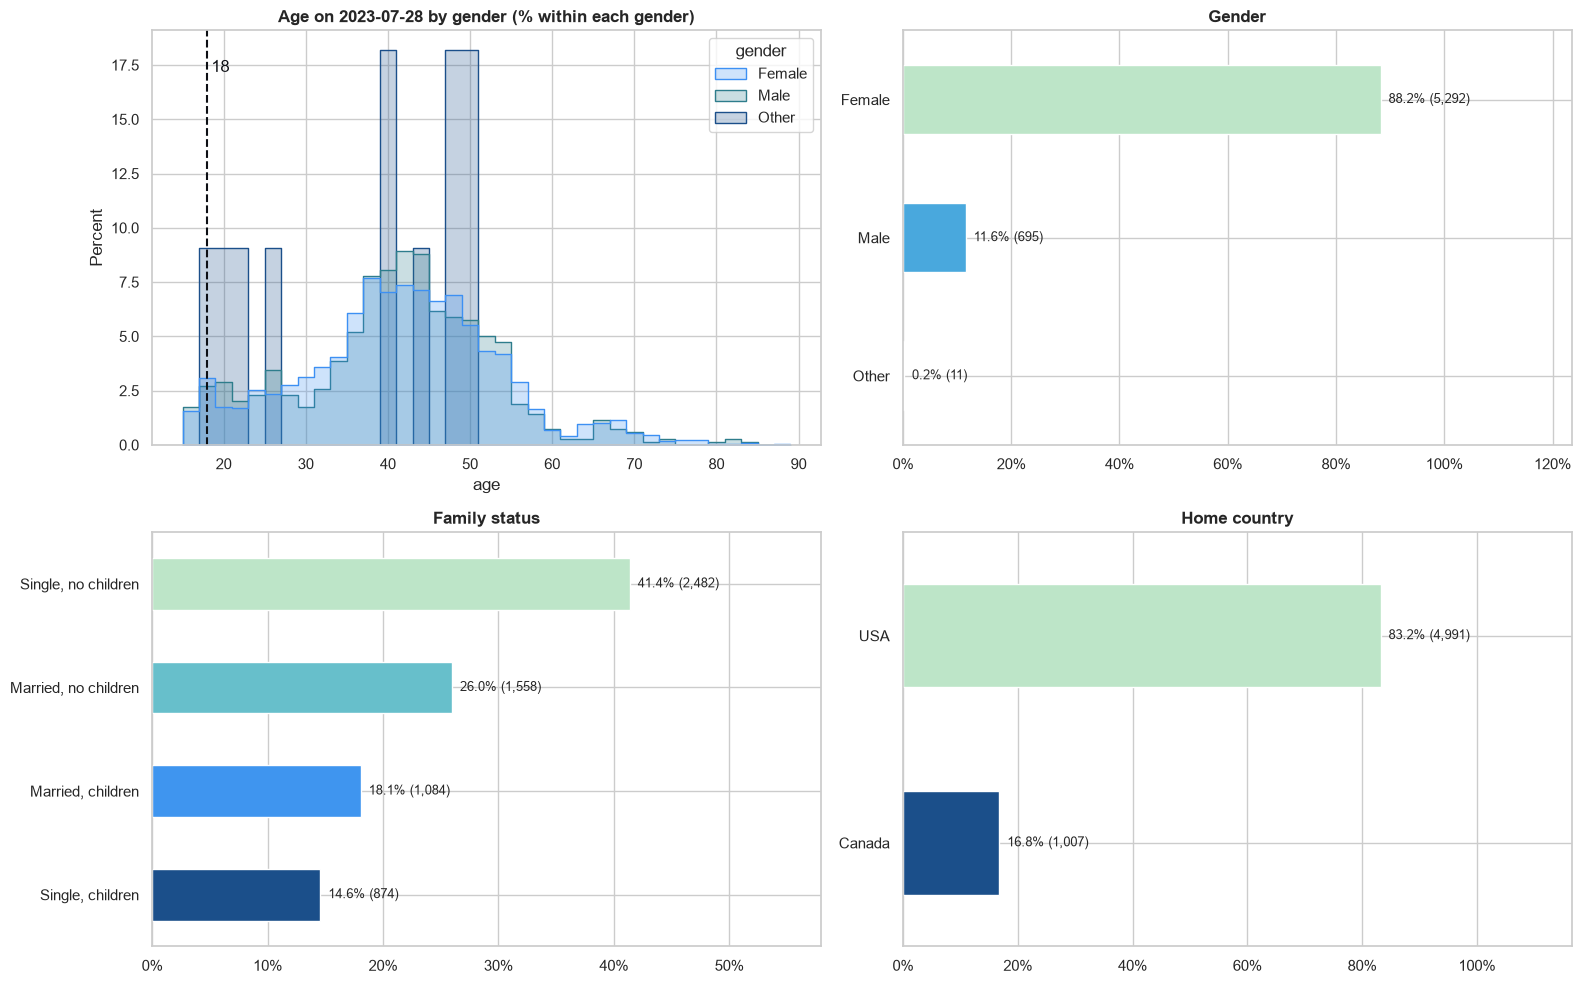

Users with children: 1,958 of 5,998 (32.6%)


,count,mean,std,min,25%,50%,75%,max
gender_label,,,,,,,,
Female,5292.0,40.9,12.1,16.0,34.0,41.0,48.0,88.0
Male,695.0,40.6,11.9,16.0,34.0,41.0,48.0,84.0
Other,11.0,36.5,12.9,17.0,24.0,40.0,47.5,50.0


In [35]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
ax = axes[0, 0]
# step outlines + % within each gender, so the small groups are comparable to the large female group
# ("Other" has only 11 users, so its outline is jumpy – too few for a real distribution)
sns.histplot(data=users, x="age_years", hue="gender_label", hue_order=["Female", "Male", "Other"],
             stat="percent", common_norm=False, element="step", alpha=.25, bins=range(15, 90, 2),
             ax=ax, palette=[PALETTE[0], PALETTE[2], PALETTE[3]])
ax.axvline(18, color=PALETTE[4], ls="--"); ax.text(18.5, ax.get_ylim()[1] * .9, "18", color=PALETTE[4])
ax.set_title("Age on 2023-07-28 by gender (% within each gender)", fontweight="bold"); ax.set_xlabel("age")
sns.move_legend(ax, "upper right", title="gender")

bar_with_labels(users["gender_label"].value_counts(), axes[0, 1], "Gender", horizontal=True)
bar_with_labels(users["family_status"].value_counts(), axes[1, 0], "Family status", horizontal=True)
bar_with_labels(users["home_country"].value_counts(), axes[1, 1], "Home country", horizontal=True)
plt.tight_layout(); plt.show()

print(f"Users with children: {users['has_children'].sum():,} of {len(users):,} ({users['has_children'].mean():.1%})")
display(users.groupby("gender_label")["age_years"].describe().round(1))

The typical *cohort* customer is a woman in her mid-30s to late 40s (middle half of users aged 34–48, median 41). The cohort is 88 % female, 12 % male and 0.2 % other – a result of the cohort filter, since across all users only 44 % are female (see 1.2 and 3.3); 83 % live in the USA and 17 % in Canada. A third of users have children (1,958 of 5,998 = 32.6 %) – relevant for a separate Family segment. The age distribution looks the same for women and men (median 41 and the same quartiles 34–48 for both); the 11 users with gender *Other* are too few to compare, so gender is described but not used to build segments. *Numbers: chart labels and table above.*

#### 5.2.2 Age by family status

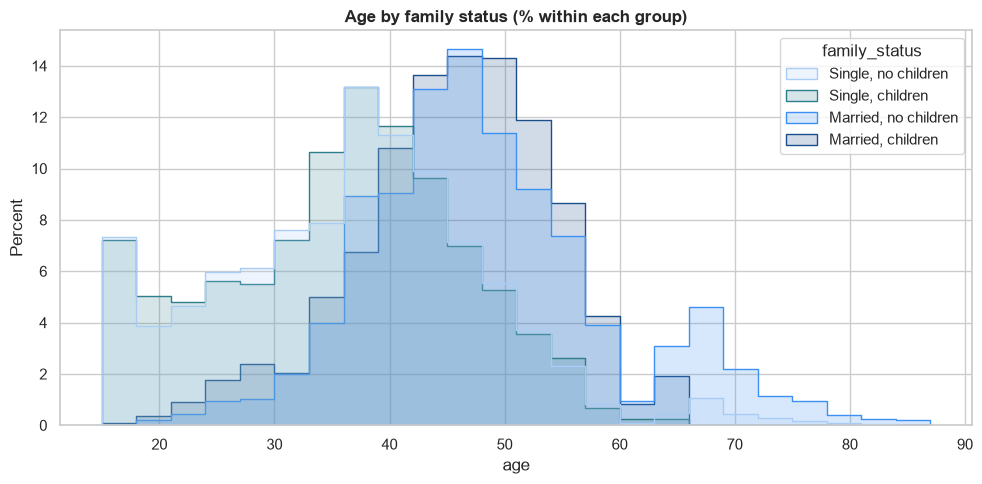

,count,age_q1,age_median,age_q3,share_%
family_status,,,,,
"Single, no children",2482,28.0,37.0,44.0,41.4
"Single, children",874,28.0,36.0,43.0,14.6
"Married, no children",1558,41.0,47.0,54.0,26.0
"Married, children",1084,40.0,46.0,51.0,18.1


In [36]:
# Third dimension: age distribution per family status
fam_order = ["Single, no children", "Single, children", "Married, no children", "Married, children"]
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=users, x="age_years", hue="family_status", hue_order=fam_order,
             stat="percent", common_norm=False, element="step", alpha=.2, bins=range(15, 90, 3),
             ax=ax, palette=[PALETTE[1], PALETTE[2], PALETTE[0], PALETTE[3]])
ax.set_title("Age by family status (% within each group)", fontweight="bold"); ax.set_xlabel("age")
plt.tight_layout(); plt.show()

age_by_fam = users.groupby("family_status")["age_years"].describe()[["count", "25%", "50%", "75%"]].reindex(fam_order)
age_by_fam["share_%"] = (age_by_fam["count"] / len(users) * 100).round(1)
display(age_by_fam.rename(columns={"25%": "age_q1", "50%": "age_median", "75%": "age_q3"}).astype({"count": int}))

**Age by family status:** married users are about 10 years older than single users (median 46–47 vs 36–37), with or without children. Family status and age overlap, which helps to *describe* segments later (e.g. Family Crew vs Couples & Friends). *Numbers: table above.*

#### 5.2.3 Who books – and who only browses?

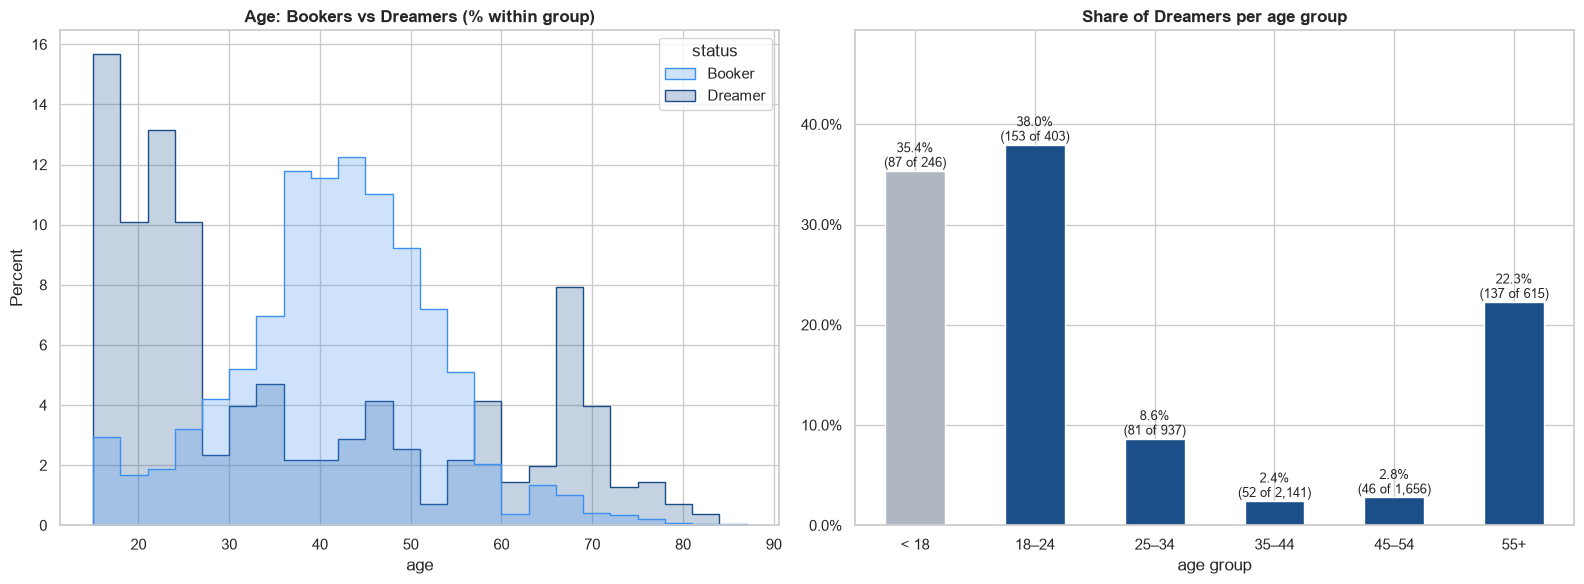

,count,25%,50%,75%
status,,,,
Booker,5442.0,35.0,42.0,48.0
Dreamer,556.0,20.0,28.0,54.0


In [37]:
# Third dimension: age of Bookers vs Dreamers (0 valid trips, from the user-level table)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(data=users, x="age_years", hue="status", hue_order=["Booker", "Dreamer"], stat="percent", common_norm=False,
             element="step", alpha=.25, bins=range(15, 90, 3), ax=axes[0], palette=[PALETTE[0], PALETTE[3]])
axes[0].set_title("Age: Bookers vs Dreamers (% within group)", fontweight="bold"); axes[0].set_xlabel("age")

age_group = pd.cut(users["age_years"], [0, 17, 24, 34, 44, 54, 100], labels=["< 18", "18–24", "25–34", "35–44", "45–54", "55+"])
by_age = users.groupby(age_group, observed=True)["status"].agg(dreamers=lambda s: (s == "Dreamer").sum(), users="size")
share = by_age["dreamers"] / by_age["users"] * 100
# "< 18" in gray: excluded later (mostly the placeholder birth year 2006)
bar_colors = ["#B0B7C3" if group == "< 18" else PALETTE[3] for group in share.index]
share.plot(kind="bar", ax=axes[1], color=bar_colors, rot=0)
for i, (s, n, u) in enumerate(zip(share, by_age["dreamers"], by_age["users"])):
    axes[1].text(i, s, f"{s:.1f}%\n({n} of {u:,})", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, share.max() * 1.3); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_title("Share of Dreamers per age group", fontweight="bold"); axes[1].set_xlabel("age group")
plt.tight_layout(); plt.show()

display(users.groupby("status")["age_years"].describe()[["count", "25%", "50%", "75%"]].round(1))

**Dreamers are much younger – or older – than bookers** (median age 28 vs 42; 34 vs 42 without the 2006 birth-year spike, see 3.7). Over a third of users aged 18–24 and about a fifth of the 55+ group never kept a booking, compared with only 2–3 % of users aged 35–54. The under-18 bar is shown but not interpreted: 82 of its 87 Dreamers were born in 2006, where many birthdates are likely placeholders (3.7). For the perk plan this means the Dreamers’ perk (no cancellation fees, pilot: 48-h Fare Lock) should be communicated in a way that speaks to young adults and seniors.

#### 5.2.4 Where do customers live?

Interactive maps (zoom and hover in Colab / VS Code). *The same maps are rebuilt in Tableau from the latitude / longitude columns.*

In [38]:
import plotly.express as px

def show_map(fig):
    try:
        fig.show()
    except ValueError as err:   # nbformat missing in this Python → see the install step in 1 (restart the kernel once)
        print("Map not shown:", str(err).splitlines()[0])

# group by city AND airport: "Portland" exists twice (PDX Oregon, PWM Maine)
home = (users.groupby(["home_city", "home_airport", "home_airport_lat", "home_airport_lon"]).size()
        .reset_index(name="users"))
home["label"] = home["home_city"] + " (" + home["home_airport"] + ")"
home["share_%"] = (home["users"] / home["users"].sum() * 100).round(1)

# Tile map: light basemap, bubbles sized AND colored by users (pale → navy = few → many)
fig = px.scatter_map(home, lat="home_airport_lat", lon="home_airport_lon",
                     size="users", color="users",
                     color_continuous_scale=[PALETTE[1], PALETTE[0], PALETTE[3]],
                     range_color=[0, home["users"].quantile(0.95)],   # so New York / LA don't wash out the rest
                     hover_name="label",
                     hover_data={"users": True, "share_%": True, "home_airport_lat": False, "home_airport_lon": False},
                     size_max=30, opacity=0.85, zoom=2.2, center={"lat": 45, "lon": -98},
                     map_style="carto-positron", height=550,
                     title="Where cohort users live – users per home airport")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0), coloraxis_colorbar=dict(title="users"))
show_map(fig)

display(home.sort_values("users", ascending=False).head(10)[["label", "users", "share_%"]].reset_index(drop=True))

,label,users,share_%
0,New York (LGA),362,6.0
1,Los Angeles (LAX),325,5.4
2,New York (JFK),318,5.3
3,Dallas (DAL),117,2.0
4,Calgary (YYC),101,1.7
5,San Francisco (SFO),80,1.3
6,Austin (AUS),78,1.3
7,San Jose (SJC),75,1.3
8,Ottawa (YOW),74,1.2
9,Nashville (BNA),74,1.2


Customers come from large US and Canadian cities (top 10 home locations above). Home location is used to calculate trip distance (section 4), not as a segmentation feature.

### 5.3 Flights – how many, how far, at what price?
*Source table: `flights` – here the 13,157 valid bookings that include a flight.*

> **Why 13,157 and not 13,717 (the flights table in 1.3)?** The flights table has one row for every trip that ever had a flight booked – including **560 trips that were canceled** afterwards. A canceled flight never happened, so it is left out of travel behavior (3.6): 13,717 − 560 = **13,157 valid flight bookings**.

#### 5.3.1 Seats and checked bags

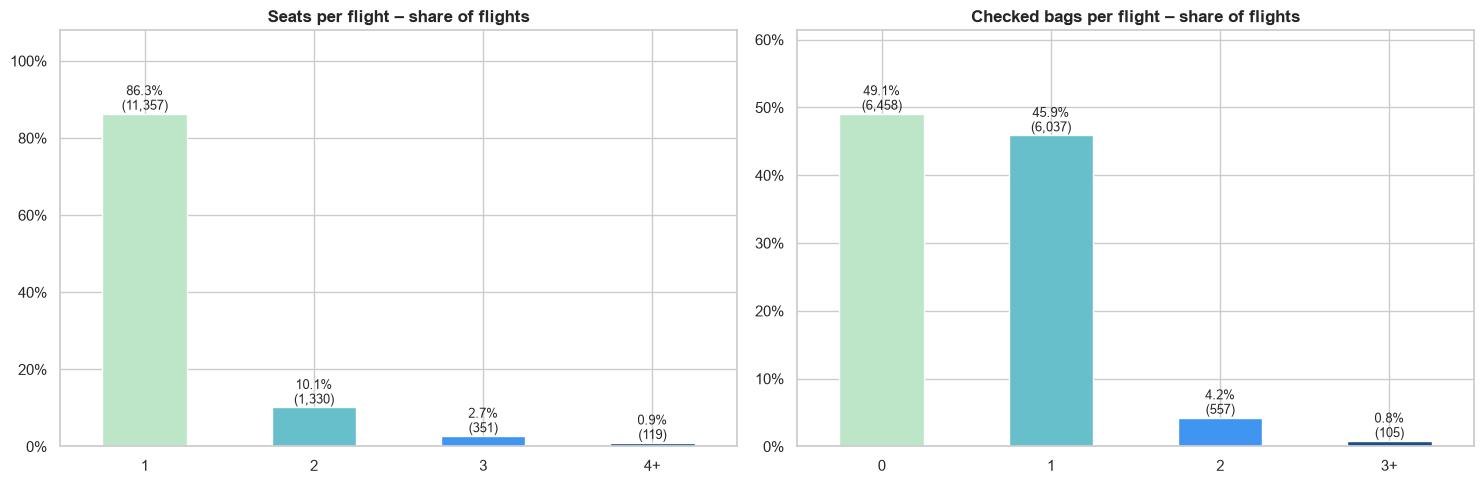

Flights with 2+ seats: 1,800 of 13,157 (13.7%)


,seats,rooms,checked_bags
No children,1.17,1.19,0.56
Has children,1.2,1.2,0.6


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
seats = bookings["seats"].dropna().astype(int).clip(upper=4).astype(str).replace({"4": "4+"}).value_counts().sort_index()
bags = bookings["checked_bags"].dropna().astype(int).clip(upper=3).astype(str).replace({"3": "3+"}).value_counts().sort_index()
bar_with_labels(seats, axes[0], "Seats per flight – share of flights")
bar_with_labels(bags, axes[1], "Checked bags per flight – share of flights")
plt.tight_layout(); plt.show()

s = bookings["seats"].dropna() # flights only – hotel-only bookings have no seats
print(f"Flights with 2+ seats: {(s >= 2).sum():,} of {len(s):,} ({(s >= 2).mean():.1%})")
party = bookings.groupby("has_children")[["seats", "rooms", "checked_bags"]].mean().round(2)
party.index = ["No children", "Has children"]
display(party)

Most flights are for one person with at most one bag – about 14 % of flights have 2+ seats (1,800 of 13,157, printed above).

**Surprise:** users with children book almost the same party size as users without (1.20 vs 1.17 seats). `has_children` alone does **not** mean family travel – many parents travel alone. That's why the Family Crew rule needs both: children **and** 2+ seats or rooms on average.

#### 5.3.2 Distance

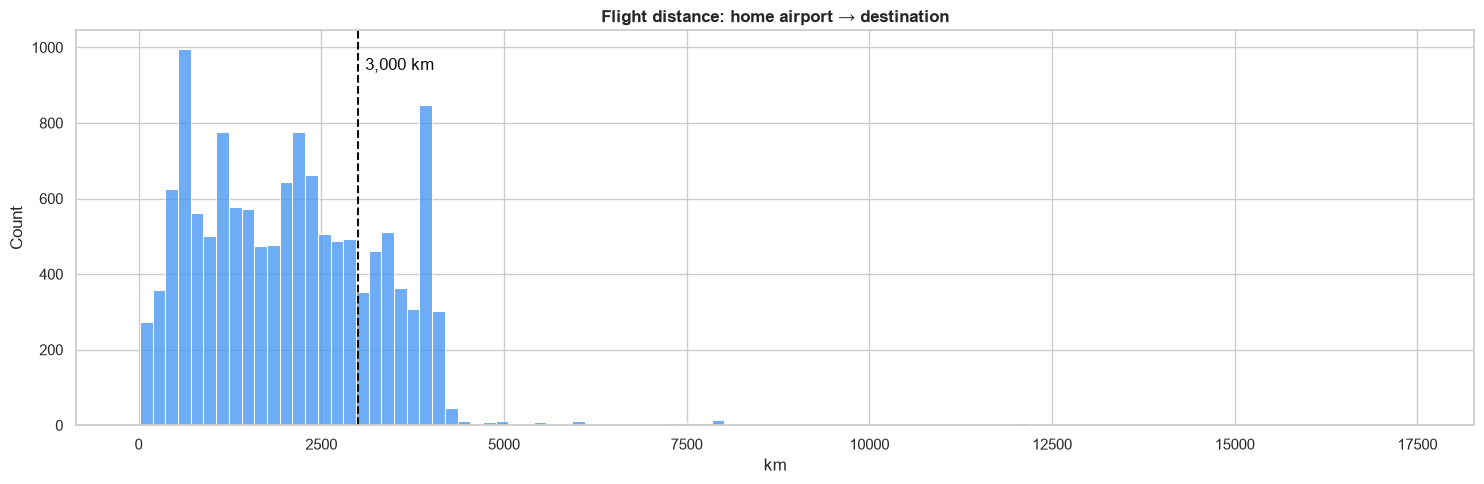

Median distance: 2,001 km | flights over 3,000 km: 3,348 of 13,157 (25.4%)


In [40]:
fig, ax = plt.subplots(figsize=(15, 5))
sns.histplot(bookings["distance_km"].dropna(), bins=100, color=PALETTE[0], ax=ax)
ax.axvline(3000, color=PALETTE[4], ls="--"); ax.text(3100, ax.get_ylim()[1] * .9, "3,000 km", color=PALETTE[4])
ax.set_title("Flight distance: home airport → destination", fontweight="bold"); ax.set_xlabel("km")
plt.tight_layout(); plt.show()
dist = bookings["distance_km"].dropna()
print(f"Median distance: {dist.median():,.0f} km | flights over 3,000 km: {(dist > 3000).sum():,} of {len(dist):,} ({(dist > 3000).mean():.1%})")

Most flights are domestic or cross-border (median about 2,000 km). A long tail of long-haul trips (> 3,000 km: 3,348 of 13,157 flights = 25.4 %) defines the Long-haul Travelers.

#### 5.3.3 Destinations

In [41]:
dest = (bookings.dropna(subset=["destination"])
        .groupby(["destination", "destination_airport_lat", "destination_airport_lon"]).size()
        .reset_index(name="trips"))
dest["share_%"] = (dest["trips"] / dest["trips"].sum() * 100).round(1)

# Tile map: light basemap, bubbles sized AND colored by trips (pale → navy = few → many)
fig = px.scatter_map(dest, lat="destination_airport_lat", lon="destination_airport_lon",
                     size="trips", color="trips",
                     color_continuous_scale=[PALETTE[1], PALETTE[0], PALETTE[3]],
                     range_color=[0, dest["trips"].quantile(0.95)],   # so a few big cities don't wash out the rest
                     hover_name="destination",
                     hover_data={"trips": True, "share_%": True, "destination_airport_lat": False, "destination_airport_lon": False},
                     size_max=35, opacity=0.85, zoom=1.4, center={"lat": 38, "lon": -60},
                     map_style="carto-positron", height=550,
                     title="Where they fly to – valid bookings per destination")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0), coloraxis_colorbar=dict(title="trips"))
show_map(fig)

print(f"Top 10 destinations ({dest['trips'].sum():,} flights with a destination):")
display(dest.sort_values("trips", ascending=False).head(10)[["destination", "trips", "share_%"]].reset_index(drop=True))

Top 10 destinations (13,157 flights with a destination):


,destination,trips,share_%
0,New York,1899,14.4
1,Los Angeles,993,7.5
2,Toronto,708,5.4
3,Chicago,687,5.2
4,Houston,550,4.2
5,Montreal,437,3.3
6,Phoenix,412,3.1
7,Philadelphia,387,2.9
8,San Antonio,361,2.7
9,Dallas,354,2.7


Most trips go to other North American cities (New York alone takes 14 % of flights – top 10 above), with a smaller set of international long-haul destinations – the long tail seen in the distance chart.

#### 5.3.4 Fares by distance and seats

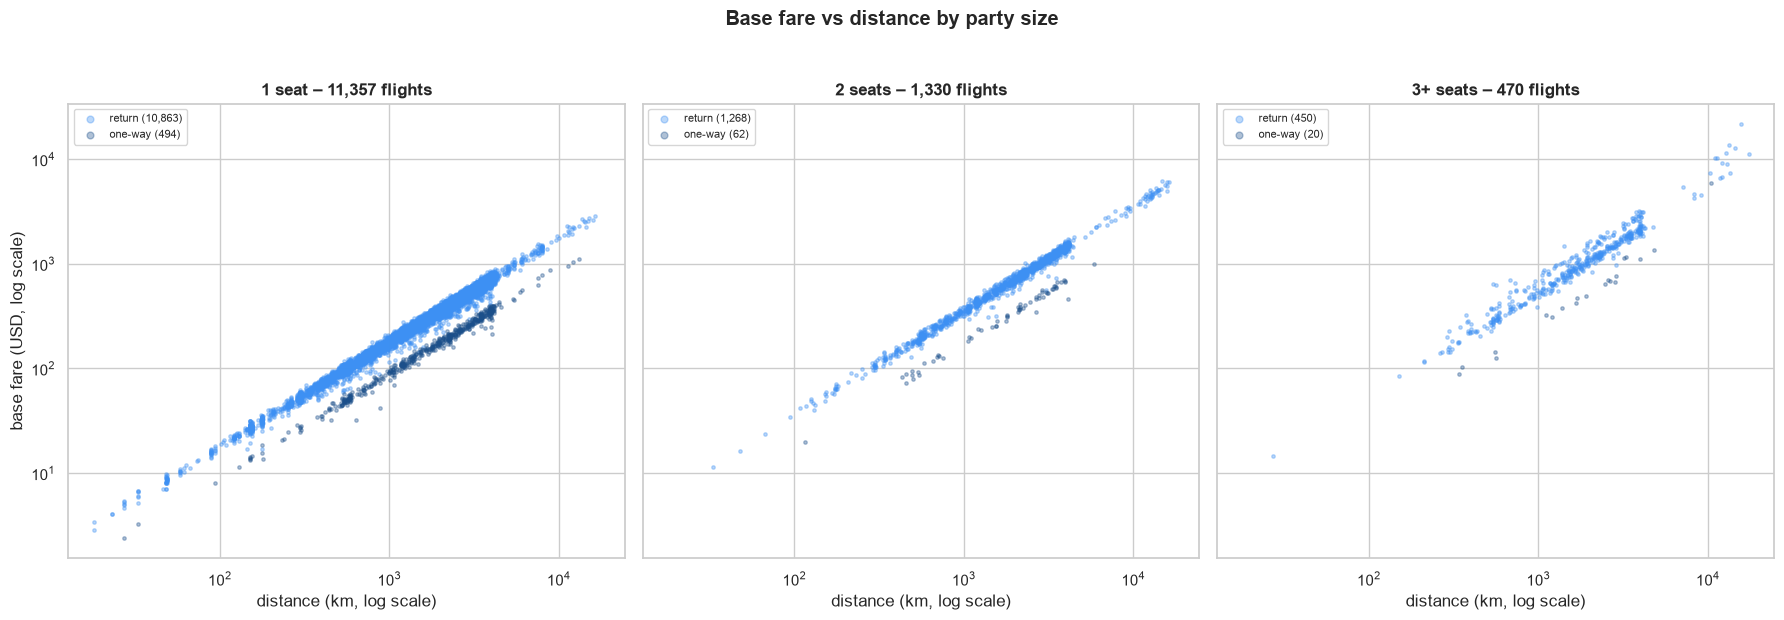

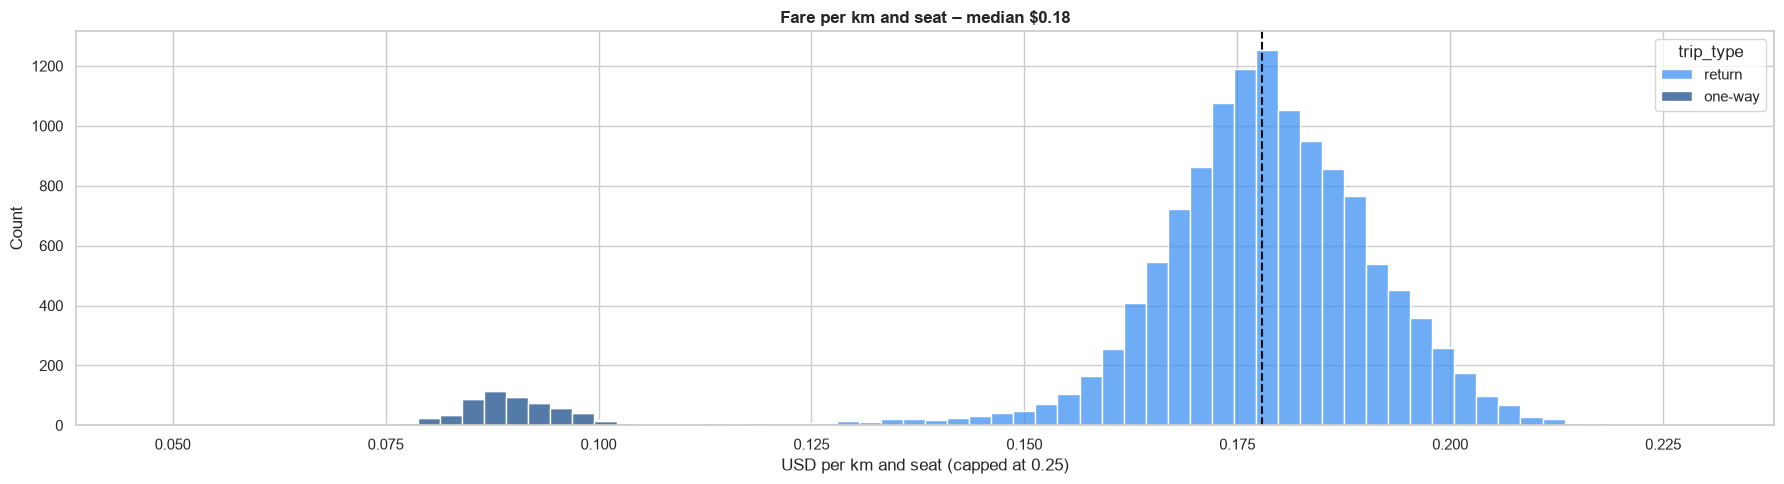

,flights,share_%,median_fare_usd,mean_bags
distance_band,,,,
"up to 3,000 km",9809,74.6,278.88,0.56
"long-haul (> 3,000 km)",3348,25.4,668.34,0.6


In [42]:
# Fare vs distance by party size: base_fare_usd is the price for all seats of a booking
flights_b = bookings.dropna(subset=["distance_km"]).copy()
flights_b["seats_group"] = flights_b["seats"].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
flights_b["trip_type"] = np.where(flights_b["return_flight_booked"] == False, "one-way", "return")
flights_b["fare_per_km_seat"] = flights_b["base_fare_usd"] / flights_b["distance_km"] / flights_b["seats"]
trip_colors = {"return": PALETTE[0], "one-way": PALETTE[3]}

# 1) Small multiples: one panel per party size, one-way flights highlighted
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
for ax, group in zip(axes, ["1", "2", "3+"]):
    g = flights_b[flights_b["seats_group"] == group]
    for trip_type, color in trip_colors.items():
        part = g[g["trip_type"] == trip_type]
        ax.scatter(part["distance_km"], part["base_fare_usd"], s=6, alpha=.35, color=color, label=f"{trip_type} ({len(part):,})")
    ax.set_title(f"{group} seat{'s' if group != '1' else ''} – {len(g):,} flights", fontweight="bold")
    ax.set_xlabel("distance (km, log scale)"); ax.set_xscale("log"); ax.set_yscale("log")
    ax.legend(fontsize=8, markerscale=2, loc="upper left")
axes[0].set_ylabel("base fare (USD, log scale)")
fig.suptitle("Base fare vs distance by party size", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

# 2) Fare per km and seat: the price rule behind the scatter (one-way flights in navy)
med = flights_b["fare_per_km_seat"].median()
fig, ax = plt.subplots(figsize=(18, 5))
sns.histplot(data=flights_b.assign(fare_per_km_seat=flights_b["fare_per_km_seat"].clip(upper=0.25)),
             x="fare_per_km_seat", hue="trip_type", hue_order=["return", "one-way"], palette=trip_colors,
             bins=70, multiple="stack", ax=ax)
ax.axvline(med, color=PALETTE[4], ls="--")
ax.set_title(f"Fare per km and seat – median ${med:.2f}", fontweight="bold")
ax.set_xlabel("USD per km and seat (capped at 0.25)")
plt.tight_layout(); plt.show()

# Table: long-haul vs shorter flights
flights_b["distance_band"] = np.where(flights_b["distance_km"] > 3000, "long-haul (> 3,000 km)", "up to 3,000 km")
band_order = ["up to 3,000 km", "long-haul (> 3,000 km)"]
fares = flights_b.groupby("distance_band").agg(flights=("trip_id", "count"), median_fare_usd=("base_fare_usd", "median"),
                                               mean_bags=("checked_bags", "mean")).reindex(band_order)
fares.insert(1, "share_%", (fares["flights"] / fares["flights"].sum() * 100).round(1))
display(fares.round(2))

**Fares follow a simple rule: about $0.18 per km and seat** for a return flight (median, histogram). In the panels, each party size forms its own straight "price line", so `base_fare_usd` is the price for all seats together. The **one-way flights** (navy) form a parallel line at about half the price – all 576 one-way bookings sit in the small cluster at about $0.09 per km, because only one direction is paid. The fare therefore adds little information beyond distance, party size and one-way vs return.

The same rule explains the median price per seat (valid bookings only, table above): about $315–350 for 1 to 4 seats, because these flights have a similar median distance (~2,000 km); the few 5+ seat bookings (15) fly further (median ~3,750 km) and therefore cost more per seat.

Long-haul flights cost more than twice as much (median about $668 vs $279, table above), while checked bags rise only slightly on long-haul flights – luggage is its own behavior, not a long-haul effect (Part 3 defines Long-haul Travelers by distance only).

In [43]:
display(flights_b.assign(fare_per_seat=flights_b["base_fare_usd"] / flights_b["seats"])
        .groupby(flights_b["seats"].clip(upper=5).astype(int))
        .agg(flights=("fare_per_seat", "size"), median_fare_per_seat=("fare_per_seat", "median"),
             median_distance_km=("distance_km", "median")).round(0))

,flights,median_fare_per_seat,median_distance_km
seats,,,
1,11357,348.0,2001.0
2,1330,346.0,2057.0
3,351,315.0,1835.0
4,104,343.0,1950.0
5,15,627.0,3747.0


### 5.4 Hotels – how many rooms, how long, at what price?
*Source table: `hotels` – here the 13,896 valid bookings that include a hotel.*

> **Why 13,896 and not 14,313 (the hotels table in 1.3)?** The hotels table has one row for every trip that ever had a hotel booked – including **417 trips that were canceled** afterwards. A canceled stay never happened, so its nights, rooms and price are left out of travel behavior (3.6): 14,313 − 417 = **13,896 valid hotel bookings**.

#### 5.4.1 Rooms, price per night and hotel chains

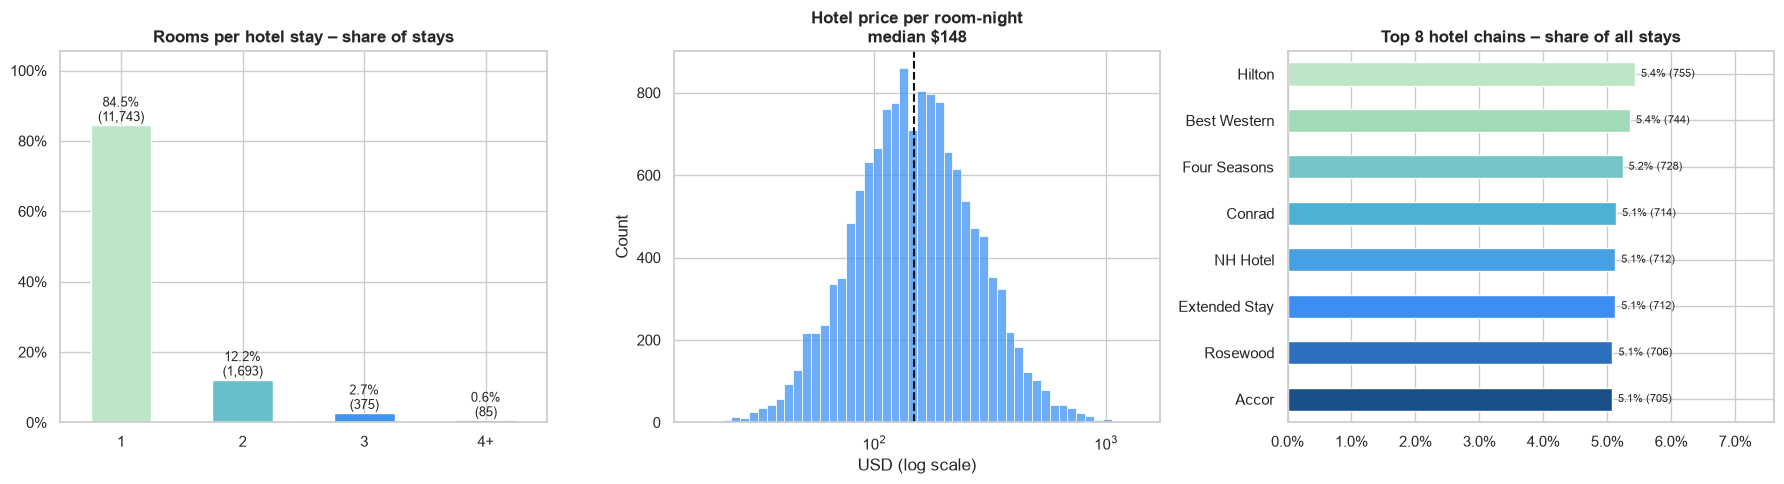

Hotel stays with 2+ rooms: 2,153 of 13,896 (15.5%)


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
rooms = bookings["rooms"].dropna().astype(int).clip(upper=4).astype(str).replace({"4": "4+"}).value_counts().sort_index()
bar_with_labels(rooms, axes[0], "Rooms per hotel stay – share of stays")
price = bookings["hotel_per_room_usd"].dropna()
sns.histplot(price[price > 0], bins=50, log_scale=True, ax=axes[1], color=PALETTE[0])
axes[1].axvline(price.median(), color=PALETTE[4], ls="--")
axes[1].set_title(f"Hotel price per room-night\nmedian ${price.median():,.0f}", fontweight="bold"); axes[1].set_xlabel("USD (log scale)")
# chain = brand part of hotel_name ("Brand - City"); 957 hotels belong to 20 chains
chains = bookings["hotel_name"].dropna().str.split(" - ").str[0].value_counts()
bar_with_labels(chains.head(8), axes[2], "Top 8 hotel chains – share of all stays", horizontal=True, total=chains.sum(), fontsize=8)
plt.tight_layout(); plt.show()

r = bookings["rooms"].dropna()
print(f"Hotel stays with 2+ rooms: {(r >= 2).sum():,} of {len(r):,} ({(r >= 2).mean():.1%})")

Most stays are one room (about 15 % have 2+ rooms – 2,153 of 13,896, printed above). Room prices are right-skewed around a median of about $148 per night. Stays are spread over many chains, no single chain dominates (each of the top chains has only about 5 % of stays).

#### 5.4.2 Nights by start weekday

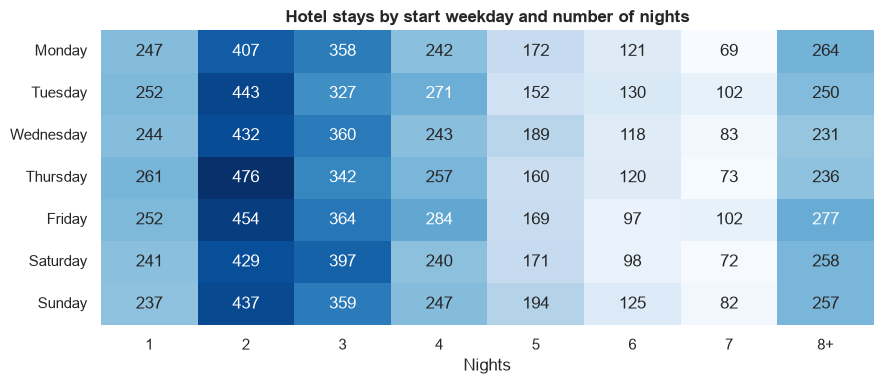

Median nights: 3.0


In [45]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (bookings.dropna(subset=["nights_calc"])
        .assign(nights=lambda d: d["nights_calc"].astype(int).clip(upper=8).astype(str).replace("8", "8+"))
        .pivot_table(index="start_weekday", columns="nights", values="trip_id", aggfunc="count")
        .reindex(days))
heat = heat[[c for c in [str(i) for i in range(1, 8)] + ["8+"] if c in heat.columns]]
plt.figure(figsize=(9, 4))
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".0f", cbar=False)
plt.title("Hotel stays by start weekday and number of nights", fontweight="bold"); plt.xlabel("Nights"); plt.ylabel("")
plt.tight_layout(); plt.show()
print("Median nights:", bookings["nights_calc"].median())

Short stays of 1–3 nights dominate on every weekday – there is no weekday where long stays cluster.

#### 5.4.3 Nights by booking type

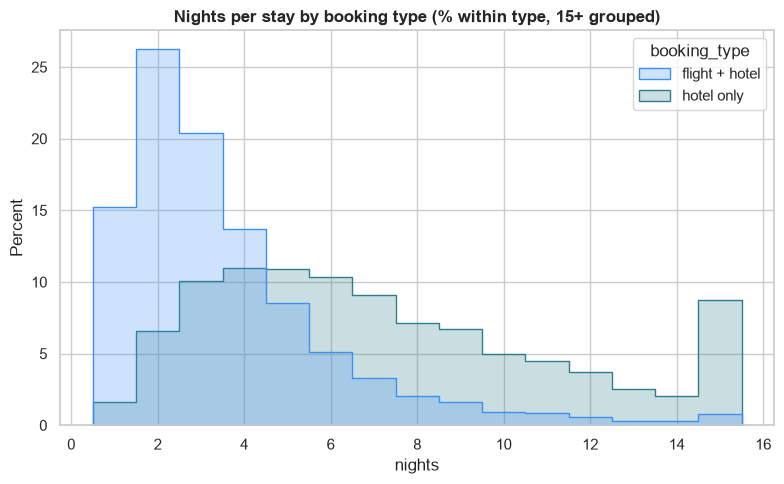

,stays,median_nights,median_price_usd
booking_type,,,
flight + hotel,11143,3.0,148.0
hotel only,2332,6.0,147.5


In [46]:
# Third dimension: nights per stay for packages (flight + hotel) vs hotel-only trips
types = ["flight + hotel", "hotel only", "flight only"]
type_colors = dict(zip(types, [PALETTE[0], PALETTE[2], PALETTE[3]]))
stays = bookings[bookings["booking_type"].isin(types[:2])].dropna(subset=["nights_calc"])
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=stays.assign(nights=stays["nights_calc"].astype(float).clip(upper=15)), x="nights",
             hue="booking_type", hue_order=types[:2], stat="percent", common_norm=False, element="step",
             alpha=.25, discrete=True, palette=type_colors, ax=ax)
ax.set_title("Nights per stay by booking type (% within type, 15+ grouped)", fontweight="bold")
plt.tight_layout(); plt.show()

display(stays.groupby("booking_type").agg(stays=("trip_id", "count"), median_nights=("nights_calc", "median"),
                                          median_price_usd=("hotel_per_room_usd", "median")).reindex(types[:2]))

**Hotel-only stays are twice as long** as package stays (median 6 vs 3 nights) at the same price per night (table above). They are the one clearly different travel style in the data → a separate **Hotel Stayers** segment.

### 5.5 Trips across tables – spend, discounts and timing
*Combines `sessions` (discounts, booking date), `flights` and `hotels` for the 15,489 valid bookings.*

#### 5.5.1 Trip spend

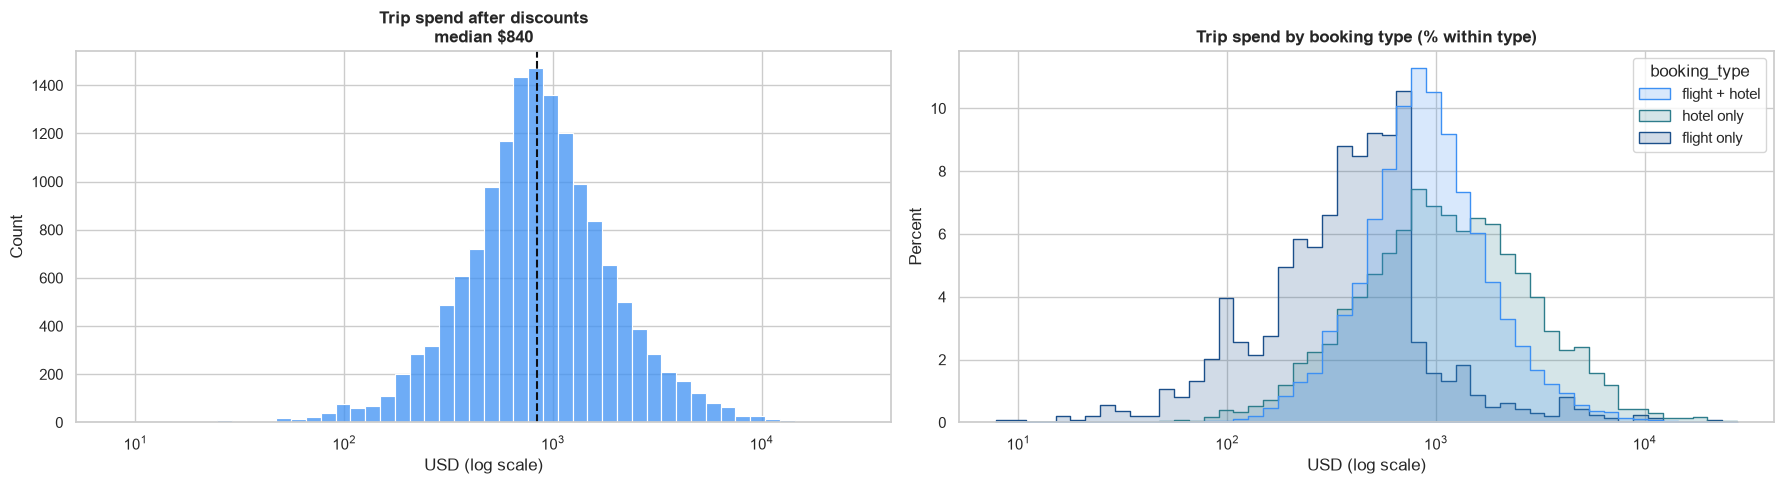

Trips without spend (invalid hotel dates): 421


,trips,share_%,median_spend_usd
booking_type,,,
flight + hotel,11564,74.7,880.85
hotel only,2332,15.1,1093.20
flight only,1593,10.3,393.00


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
spend = bookings[bookings["trip_spend_usd"] > 0]
sns.histplot(spend["trip_spend_usd"], bins=50, log_scale=True, ax=axes[0], color=PALETTE[0])
axes[0].axvline(spend["trip_spend_usd"].median(), color=PALETTE[4], ls="--")
axes[0].set_title(f"Trip spend after discounts\nmedian ${spend['trip_spend_usd'].median():,.0f}", fontweight="bold"); axes[0].set_xlabel("USD (log scale)")
# Third dimension: spend per booking type
sns.histplot(data=spend, x="trip_spend_usd", hue="booking_type", hue_order=types, stat="percent", common_norm=False,
             element="step", alpha=.2, bins=50, log_scale=True, ax=axes[1], palette=type_colors)
axes[1].set_title("Trip spend by booking type (% within type)", fontweight="bold"); axes[1].set_xlabel("USD (log scale)")
plt.tight_layout(); plt.show()

print("Trips without spend (invalid hotel dates):", bookings["trip_spend_usd"].isna().sum())
by_type = bookings.groupby("booking_type").agg(trips=("trip_id", "count"), median_spend_usd=("trip_spend_usd", "median")).reindex(types)
by_type.insert(1, "share_%", (by_type["trips"] / by_type["trips"].sum() * 100).round(1))

display(by_type)

Spend is strongly right-skewed (log scale): most trips are mid-priced, a small share are premium. Outliers are kept (3.8); spend itself is not used for clustering in Part 3 – it is a result of party size and nights. Hotel-only trips cost the most per trip (longer stays), flight-only trips the least (table above).

#### 5.5.2 Discounts

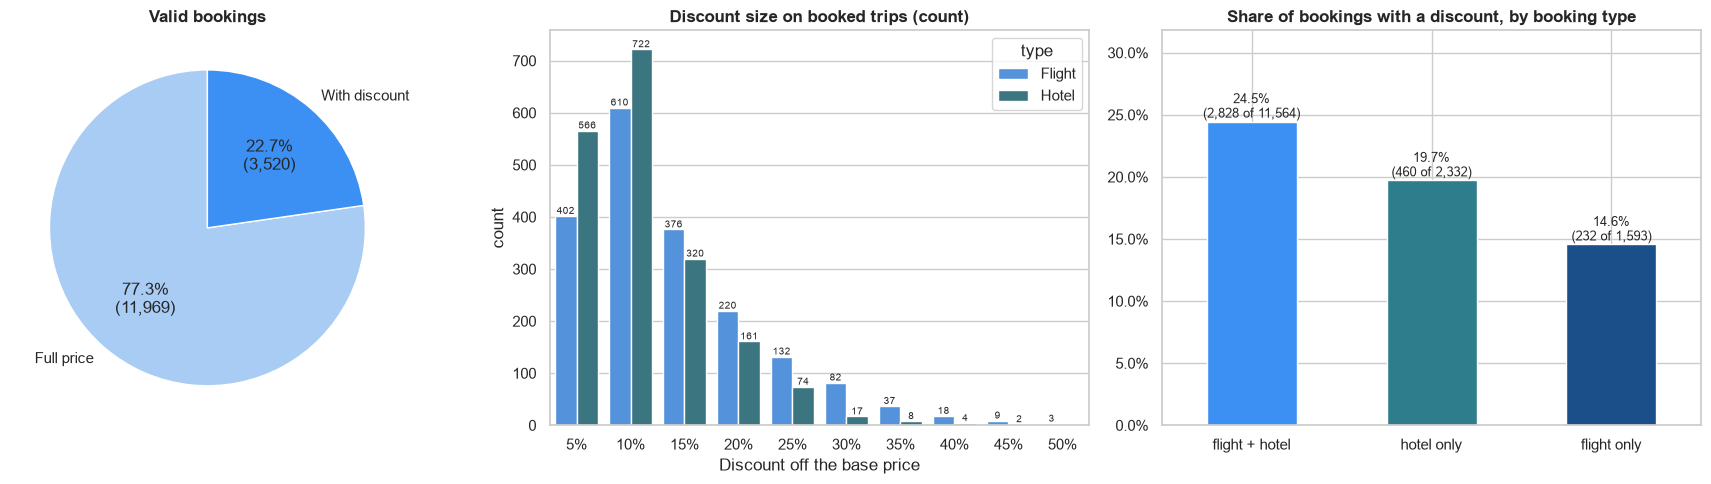

Discounts of 5–20 %: 89.7% of all 3,763 flight and hotel discounts


In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
used = bookings["discount_used"].astype(bool).map({True: "With discount", False: "Full price"}).value_counts() # share of valid bookings with a discount on the booked part
used.plot(kind="pie", ax=axes[0], colors=[PALETTE[1], PALETTE[0]], startangle=90,
          autopct=lambda p: f"{p:.1f}%\n({p * used.sum() / 100:,.0f})")
axes[0].set_ylabel(""); axes[0].set_title("Valid bookings", fontweight="bold")

# discount sizes only for the booked part (4.1 data note)
disc = pd.concat([bookings["flight_discount_amount"].where(bookings["flight_booked"] & bookings["flight_discount"]).dropna().rename("Flight"),
                  bookings["hotel_discount_amount"].where(bookings["hotel_booked"] & bookings["hotel_discount"]).dropna().rename("Hotel")], axis=1)
disc_long = disc.melt(var_name="type", value_name="discount").dropna()
disc_long["discount"] = (disc_long["discount"].round(2) * 100).astype(int)
disc_long["label"] = disc_long["discount"].astype(str) + "%"
label_order = [f"{d}%" for d in sorted(disc_long["discount"].unique())]
sns.countplot(data=disc_long, x="label", hue="type", order=label_order, ax=axes[1], palette=[PALETTE[0], PALETTE[2]])
for container in axes[1].containers:
    axes[1].bar_label(container, fontsize=7)
axes[1].set_title("Discount size on booked trips (count)", fontweight="bold"); axes[1].set_xlabel("Discount off the base price")

# Third dimension: discount use per booking type
by_type_disc = bookings.assign(discount_used=bookings["discount_used"].astype(bool)).groupby("booking_type")["discount_used"].agg(["mean", "sum", "size"]).reindex(types)
(by_type_disc["mean"] * 100).plot(kind="bar", ax=axes[2], color=[type_colors[t] for t in types], rot=0)
for i, (m, n, t) in enumerate(by_type_disc.itertuples(index=False)):
    axes[2].text(i, m * 100, f"{m:.1%}\n({n:,.0f} of {t:,})", ha="center", va="bottom", fontsize=9)
axes[2].set_ylim(0, by_type_disc["mean"].max() * 130); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[2].set_xlabel(""); axes[2].set_title("Share of bookings with a discount, by booking type", fontweight="bold")
plt.tight_layout(); plt.show()

small = disc_long["discount"].between(5, 20).mean()
print(f"Discounts of 5–20 %: {small:.1%} of all {len(disc_long):,} flight and hotel discounts")

Just under a quarter of bookings use a discount (3,520 of 15,489 = 22.7 %, counting only discounts on the booked part – see the data note in 4.1), mostly 5–20 % (about 90 % of all discounts, printed above). Packages use discounts most often (about 25 %), hotel-only trips about 20 % and flight-only trips about 15 %. Most bookings are at full price (77.3 %) – so an exclusive-discount perk should target the users who **consistently** book discounted trips (Deal Hunters), not everyone.

*Counting every offered discount would make hotel-only trips look like the most discounted (about 34 %) – an artifact: many of them carry a flight discount that was offered but never used (4.1).*

#### 5.5.3 Timing: weekend starts and lead time

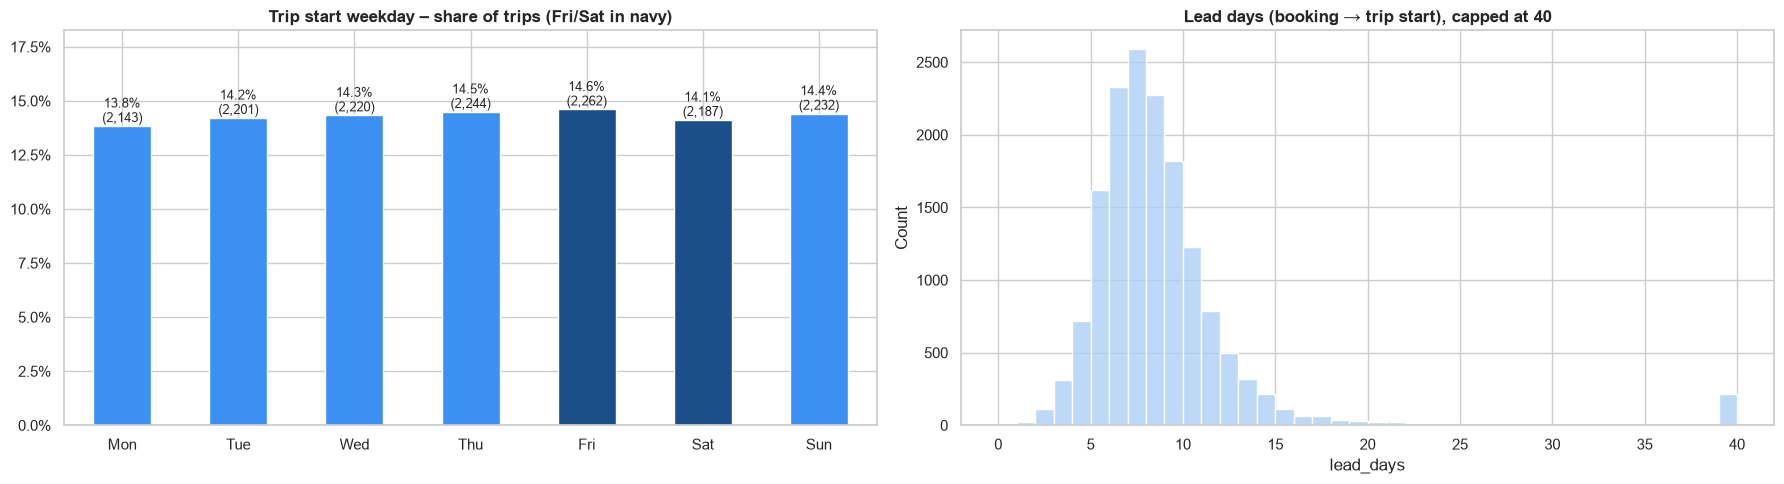

Trips starting Fri/Sat: 4,449 of 15,489 (28.7%)
Lead days median: 8.0 | 90th percentile: 12.0


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
weekday_counts = bookings["start_weekday"].value_counts().reindex(days)
weekday_colors = [PALETTE[3] if d in ("Friday", "Saturday") else PALETTE[0] for d in days]
bar_with_labels(weekday_counts, axes[0], "Trip start weekday – share of trips (Fri/Sat in navy)", color=weekday_colors)
axes[0].set_xticks(range(7), [d[:3] for d in days], rotation=0)
sns.histplot(bookings["lead_days"].clip(upper=40), bins=40, color=PALETTE[1], ax=axes[1]) # capped at 40 to avoid a long tail
axes[1].set_title("Lead days (booking → trip start), capped at 40", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Trips starting Fri/Sat: {bookings['weekend_start'].sum():,.0f} of {bookings['weekend_start'].notna().sum():,} "
      f"({bookings['weekend_start'].mean():.1%})")
print("Lead days median:", bookings["lead_days"].median(), "| 90th percentile:", bookings["lead_days"].quantile(.9))

- **Weekend starts:** every weekday gets about 14 % of trip starts (chart above). Overall, 28.7 % of trips start on a Friday or Saturday – exactly what you'd expect by chance (2 of 7 days = 28.6 %), so there is no general weekend bias. A **user-level** weekend segment was tested in Part 3 (3.2) – it turned out to be chance as well, so it was dropped.
- **Lead time** is short for nearly everyone (median 8 days, 90 % within 12 days) → early planners vs last-minute bookers can't be separated, so lead time is a flat signal and **not used** for segmentation.

#### 5.5.4 Correlation of trip features

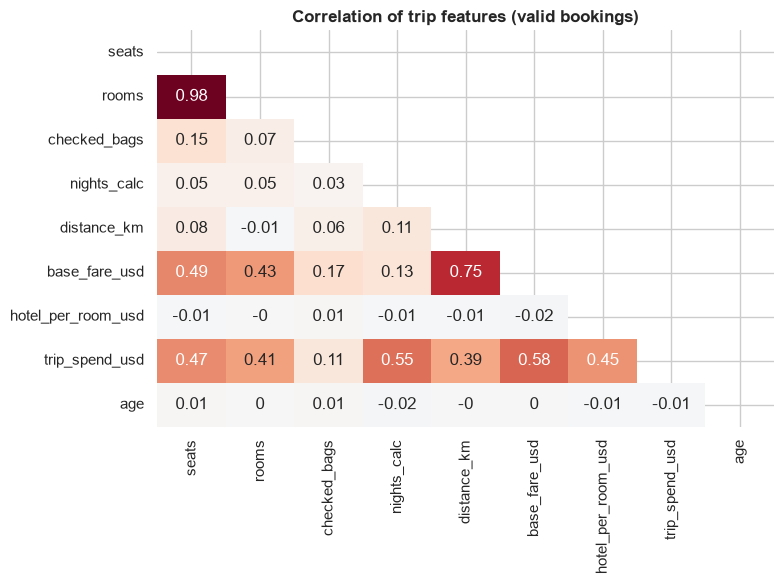

In [50]:
corr_cols = ["seats", "rooms", "checked_bags", "nights_calc", "distance_km", "base_fare_usd", "hotel_per_room_usd", "trip_spend_usd", "age"]
corr = bookings[corr_cols].astype(float).corr().round(2)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False)
plt.title("Correlation of trip features (valid bookings)", fontweight="bold"); plt.tight_layout(); plt.show()

- **Seats and rooms are almost the same signal (r = 0.98)** → in clustering, use one combined party-size feature instead of both, otherwise party size counts twice.
- Spend is driven by nights (0.55), fare (0.58) and party size; distance mainly works through the fare.
- Checked bags are only weakly linked to party size (0.15) → luggage is its own behavior, not a side effect of group size.
- **Age is unrelated to every trip feature (|r| ≤ 0.02)** → segment on **behavior**, and use demographics to describe the segments afterwards.

## 6 – Export & Key Findings

In [51]:
# Save next to the input data (local data folder); only create "data/" if no local folder exists yet
OUTPUT_DIR = DATA_DIR if DATA_DIR is not None else Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)
df.to_csv(OUTPUT_DIR / "sessions_clean.csv", index=False)
print("Saved:", (OUTPUT_DIR / "sessions_clean.csv").resolve(), "|", df.shape)
df.dtypes.to_frame("dtype").T

Saved: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data\sessions_clean.csv | (49211, 59)


,session_id,user_id,trip_id,session_start,session_end,page_clicks,flight_discount,flight_discount_amount,flight_booked,hotel_discount,hotel_discount_amount,hotel_booked,cancellation,session_count,gender,married,has_children,home_country,home_city,home_airport,home_airport_lat,home_airport_lon,origin_airport,destination,destination_airport,seats,return_flight_booked,departure_time,return_time,checked_bags,trip_airline,destination_airport_lat,destination_airport_lon,base_fare_usd,hotel_name,rooms,check_in_time,check_out_time,hotel_per_room_usd,hotel_city,home_airport_name,destination_airport_name,invalid_hotel_dates,nights_calc,trip_cancelled,valid_booking,age,tenure_months,is_minor,session_minutes,booking_type,trip_start,start_weekday,weekend_start,lead_days,trip_city,distance_km,discount_used,trip_spend_usd
dtype,str,int64,str,datetime64[us],datetime64[us],int64,bool,float64,bool,bool,float64,bool,bool,int64,str,bool,bool,str,str,str,float64,float64,str,str,str,Int64,boolean,datetime64[us],datetime64[us],Int64,str,float64,float64,float64,str,Int64,datetime64[us],datetime64[us],float64,object,str,str,bool,Int64,bool,bool,Int64,float64,boolean,float64,str,datetime64[us],str,object,float64,str,float64,object,float64


If the notebook ran from a local folder that is not synced with Google Drive, upload the new `sessions_clean.csv` to the Drive `data` folder so Part 2 and Tableau use the same cleaned data.

### Key findings
1. **Cohort:** 49,211 sessions from 5,998 users (Jan 4 – Jul 28, 2023); 83 % live in the USA; 88 % are female – but only because of the "more than 7 sessions" rule: across all users 44 % are female and 55 % male (1.2, 3.3), so gender is not used for perks.
2. **Most sessions are browsing:** about two thirds of sessions end without a booking (66.1 %, 5.1); 556 of 5,998 users (9.3 %, 3.6) never kept a booking → a dedicated *Dreamers* segment.
3. **Data quality fixed, no rows dropped:** hotel nights recalculated from dates (raw values count 24-hour periods), 2.9 % invalid hotel dates flagged (3.5), 50 cancellation sessions without flight details left missing (3.2), 610 canceled trips excluded from travel behavior, 246 under-18 users flagged (4.1 %, 3.7).
4. **Strong behavioral signals:** party size (seats ≈ rooms), checked bags, trip length, distance, discount use (22.7 % of bookings, 5.5) and hotel-only trips (twice as long, 5.4): – Part 3 tests which of them are real habits (checked bags and discount use turn out to be chance). Having children or being a certain age does **not** predict *how* bookers travel – but age strongly predicts *whether* someone books **at all**: Dreamers are mostly 18–24 or 55+ (5.2.3).
5. **Flat signals:** clicks per minute, sessions per user (5.1) and lead time (5.5) barely vary → not used for segmentation.

**Next:** Part 2 builds one row per user from these columns (`user_level_table.csv`, cross-checked with this table in 4.2) and defines the segments.